In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from itertools import combinations
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.tree import DecisionTreeClassifier


# 폰트 깨지는 거 막기
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


# scikit-learn 모델 html 다이어그램 대신 일반 텍스트로 출력하게 만드는 코드
from sklearn import set_config
set_config(display='text')

In [2]:
df = pd.read_csv('bank-full.csv',sep=';')

In [3]:
print(df.shape)
display(df.head(5))

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [5]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')

In [6]:
# 각 컬럼별 고유값 확인 및 고유값 빈도 확인

result = {}

for col in df.select_dtypes(include='object').columns:
    counts = df[col].value_counts(dropna=False)
    counts = counts.rename_axis('unique_value')
    counts = counts.reset_index(name='count')
    result[col] = counts

unique_df = pd.concat(result, axis=1)

display(unique_df)

C:\Users\hasoo\AppData\Local\Temp\ipykernel_50392\4238047199.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


job            marital             education           \
     unique_value count unique_value    count unique_value    count   
0     blue-collar  9732      married  27214.0    secondary  23202.0   
1      management  9458       single  12790.0     tertiary  13301.0   
2      technician  7597     divorced   5207.0      primary   6851.0   
3          admin.  5171          NaN      NaN      unknown   1857.0   
4        services  4154          NaN      NaN          NaN      NaN   
5         retired  2264          NaN      NaN          NaN      NaN   
6   self-employed  1579          NaN      NaN          NaN      NaN   
7    entrepreneur  1487          NaN      NaN          NaN      NaN   
8      unemployed  1303          NaN      NaN          NaN      NaN   
9       housemaid  1240          NaN      NaN          NaN      NaN   
10        student   938          NaN      NaN          NaN      NaN   
11        unknown   288          NaN      NaN          NaN      NaN   

        default               housing                  loan           \
   unique_value    count unique_value    count unique_value    count   
0            no  44396.0          yes  25130.0           no  37967.0   
1           yes    815.0           no  20081.0          yes   7244.0   
2           NaN      NaN          NaN      NaN          NaN      NaN   
3           NaN      NaN          NaN      NaN          NaN      NaN   
4           NaN      NaN          NaN      NaN          NaN      NaN   
5           NaN      NaN          NaN      NaN          NaN      NaN   
6           NaN      NaN          NaN      NaN          NaN      NaN   
7           NaN      NaN          NaN      NaN          NaN      NaN   
8           NaN      NaN          NaN      NaN          NaN      NaN   
9           NaN      NaN          NaN      NaN          NaN      NaN   
10          NaN      NaN          NaN      NaN          NaN      NaN   
11          NaN      NaN          NaN      NaN          NaN      NaN   

        contact                 month            poutcome           \
   unique_value    count unique_value  count unique_value    count   
0      cellular  29285.0          may  13766      unknown  36959.0   
1       unknown  13020.0          jul   6895      failure   4901.0   
2     telephone   2906.0          aug   6247        other   1840.0   
3           NaN      NaN          jun   5341      success   1511.0   
4           NaN      NaN          nov   3970          NaN      NaN   
5           NaN      NaN          apr   2932          NaN      NaN   
6           NaN      NaN          feb   2649          NaN      NaN   
7           NaN      NaN          jan   1403          NaN      NaN   
8           NaN      NaN          oct    738          NaN      NaN   
9           NaN      NaN          sep    579          NaN      NaN   
10          NaN      NaN          mar    477          NaN      NaN   
11          NaN      NaN          dec    214          NaN      NaN   

              y           
   unique_value    count  
0            no  39922.0  
1           yes   5289.0  
2           NaN      NaN  
3           NaN      NaN  
4           NaN      NaN  
5           NaN      NaN  
6           NaN      NaN  
7           NaN      NaN  
8           NaN      NaN  
9           NaN      NaN  
10          NaN      NaN  
11          NaN      NaN

### Baseline 모델 설계하기

In [7]:
# unknown 데이터 전처리 vs 처리하지 않기 비교하기 위해 baseline model 설계하기

# 설명변수는 : y와 duration 제외하고
# 타겟변수: y
# 1. 설명변수와 타깃변수 분리
X = df.drop(columns=['duration', 'y'])
y = df['y'].map({'no': 0, 'yes': 1})

# 2. 학습/테스트 분리
# 1차: Train 60%, 임시 데이터 40%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

# 2차: Validation 20%, Test 20%
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# 3. 변수 유형 구분
numeric_features = X.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# 4. 최소한의 전처리
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

# 5. Baseline 모델
baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

# 5. Baseline 모델 생성
baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

# 6. 모델 학습 (Train)
baseline_model.fit(X_train, y_train)

# 7. 모델 예측 (Validation)
y_val_pred = baseline_model.predict(X_val)
y_val_prob = baseline_model.predict_proba(X_val)[:, 1]

# 8. 모델 성능 평가 (Validation)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

baseline_result = {
    'Experiment': 'Baseline',
    'Accuracy': accuracy_score(y_val, y_val_pred),
    'Precision': precision_score(y_val, y_val_pred),
    'Recall': recall_score(y_val, y_val_pred),
    'F1': f1_score(y_val, y_val_pred),
    'ROC-AUC': roc_auc_score(y_val, y_val_prob),
    'PR-AUC': average_precision_score(y_val, y_val_prob)
}

# 9. 성능 결과 저장 및 출력
baseline_comparison = pd.DataFrame([baseline_result])

display(baseline_comparison.round(4))

,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Baseline,0.8939,0.6827,0.1749,0.2784,0.7643,0.4057


### Permutation Importance 확인하기
- 특정 변수 값을 변경 시키는게 모델의 성능이 얼마나 떨어지는지를 측정한다.
- 이 시점에서 Permutation Importance만 확인하는 이유: 모델에 따라서 feature importance 값은 달라지기 때문이다.
- permutation 활용 방법: 예를 들어 job 열의 값을 무작위로 섞었더니 Recall이 0.80에서 0.65로 떨어졌다면 recall 기준 중요도는 약 0.15다.

In [8]:
from sklearn.inspection import permutation_importance

# 1. Permutation Importance 계산
perm_result = permutation_importance(
    baseline_model,
    X_val,
    y_val,
    scoring={
        'Recall': 'recall',
        'Precision': 'precision',
        'F1': 'f1',
        'PR-AUC': 'average_precision'
    },
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 2. 중요도 결과 정리
importance_df = pd.DataFrame({
    'Feature': X_val.columns,

    'Recall_Importance': perm_result['Recall'].importances_mean,
    'Precision_Importance': perm_result['Precision'].importances_mean,
    'F1_Importance': perm_result['F1'].importances_mean,
    'PR-AUC_Importance': perm_result['PR-AUC'].importances_mean
})

# 3. 네 지표의 평균 중요도 계산
importance_cols = [
    'Recall_Importance',
    'Precision_Importance',
    'F1_Importance',
    'PR-AUC_Importance'
]

importance_df['Mean_Importance'] = importance_df[importance_cols].mean(axis=1)

# 4. 평균 중요도가 높은 순서로 정렬
importance_df = importance_df.sort_values(
    by='Mean_Importance',
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

,Feature,Recall_Importance,Precision_Importance,F1_Importance,PR-AUC_Importance,Mean_Importance
0,poutcome,0.1243,0.3038,0.1892,0.1267,0.1860
1,month,0.0328,0.0351,0.0454,0.0858,0.0498
2,contact,0.0370,0.0038,0.0492,0.0623,0.0381
3,housing,0.0265,0.0128,0.0355,0.0228,0.0244
4,job,0.0202,0.0046,0.0266,0.0034,0.0137
5,campaign,0.0095,0.0107,0.0131,0.0066,0.0100
6,education,0.0050,0.0119,0.0073,0.0048,0.0073
7,loan,0.0059,0.0030,0.0077,0.0050,0.0054
8,balance,0.0056,0.0048,0.0075,-0.0006,0.0043
9,marital,0.0030,0.0055,0.0043,0.0029,0.0039


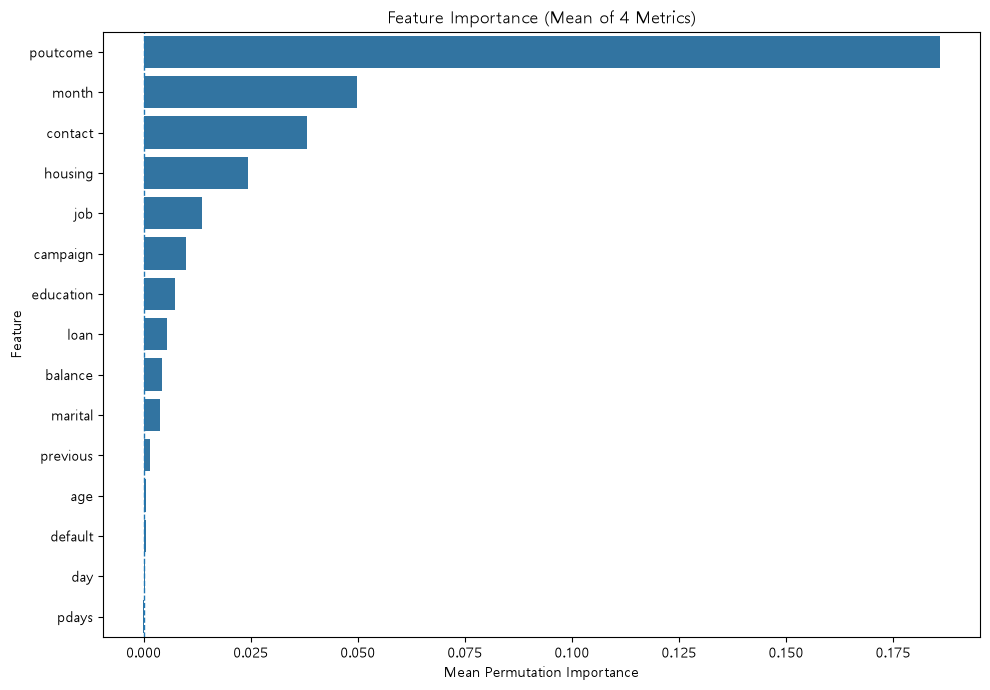

In [9]:
# 평균 중요도 기준 내림차순 정렬
plot_df = importance_df.sort_values(
    by='Mean_Importance',
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=plot_df,
    x='Mean_Importance',
    y='Feature'
)

plt.title('Feature Importance (Mean of 4 Metrics)')
plt.xlabel('Mean Permutation Importance')
plt.ylabel('Feature')
plt.axvline(x=0, linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

### 중복값 확인하기

In [10]:
# 전체 행이 완전히 동일한 중복 데이터 개수
print('중복 행 개수:', df.duplicated().sum())


중복 행 개수: 0


In [ ]:
# 전체 column 값이 동일하지 않지만 일부 동일 고객 이라고 생각할 수 있을만한 columns로 중복 조회
customer_cols = [   'age', 'job', 'marital', 'education',
    'default', 'balance', 'housing', 'loan', 'contact']

print(df.duplicated(subset=customer_cols).sum())

suspected_duplicates = df[
    df.duplicated(subset=customer_cols, keep=False)
].sort_values(customer_cols)

display(suspected_duplicates)

3141


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
40887,18,student,single,primary,no,608,no,no,cellular,12,aug,267,1,-1,0,unknown,yes
42274,18,student,single,primary,no,608,no,no,cellular,13,nov,210,1,93,1,success,yes
40744,18,student,single,unknown,no,108,no,no,cellular,10,aug,167,1,-1,0,unknown,yes
41487,18,student,single,unknown,no,108,no,no,cellular,8,sep,169,1,-1,0,unknown,yes
42954,18,student,single,unknown,no,108,no,no,cellular,9,feb,92,1,183,1,success,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43393,84,retired,married,secondary,no,81204,no,no,telephone,1,apr,390,1,94,3,success,yes
41934,92,retired,married,unknown,no,775,no,no,cellular,22,oct,313,3,-1,0,unknown,yes
42727,92,retired,married,unknown,no,775,no,no,cellular,26,jan,164,4,96,3,success,yes
44262,93,retired,married,unknown,no,775,no,no,cellular,22,jul,860,2,177,7,success,yes


In [12]:
# 원본 행 순서를 기준으로 조회
suspected_duplicates = df[
    df.duplicated(subset=customer_cols, keep=False)
].copy()

suspected_duplicates['original_row'] = suspected_duplicates.index

# 같은 고객 특성끼리 묶고 원본 행 순서대로 정렬
suspected_duplicates = suspected_duplicates.sort_values(
    by=customer_cols + ['original_row']
)

display(
    suspected_duplicates[
        ['original_row'] + customer_cols
        + ['day', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y']
    ]
)

,original_row,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
40887,40887,18,student,single,primary,no,608,no,no,cellular,12,aug,1,-1,0,unknown,yes
42274,42274,18,student,single,primary,no,608,no,no,cellular,13,nov,1,93,1,success,yes
40744,40744,18,student,single,unknown,no,108,no,no,cellular,10,aug,1,-1,0,unknown,yes
41487,41487,18,student,single,unknown,no,108,no,no,cellular,8,sep,1,-1,0,unknown,yes
42954,42954,18,student,single,unknown,no,108,no,no,cellular,9,feb,1,183,1,success,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43393,43393,84,retired,married,secondary,no,81204,no,no,telephone,1,apr,1,94,3,success,yes
41934,41934,92,retired,married,unknown,no,775,no,no,cellular,22,oct,3,-1,0,unknown,yes
42727,42727,92,retired,married,unknown,no,775,no,no,cellular,26,jan,4,96,3,success,yes
44262,44262,93,retired,married,unknown,no,775,no,no,cellular,22,jul,2,177,7,success,yes


In [13]:
# 고객 특성 컬럼
customer_cols = [
    'age', 'job', 'marital', 'education',
    'default', 'balance', 'housing', 'loan', 'contact'
]

# 마케팅 이력 및 결과 컬럼
history_cols = [
    'day', 'month', 'campaign',
    'pdays', 'previous', 'poutcome', 'y'
]

# 원본 행 인덱스 보존
suspected_duplicates = df[
    df.duplicated(subset=customer_cols, keep=False)
].copy()

suspected_duplicates['original_row'] = suspected_duplicates.index

# 동일 고객 특성 그룹을 식별할 번호
suspected_duplicates['case_id'] = (
    suspected_duplicates
    .groupby(customer_cols, dropna=False, observed=True)
    .ngroup()
)

print("중복 의심 행 수:", len(suspected_duplicates))
print("중복 의심 그룹 수:",
      suspected_duplicates['case_id'].nunique())

중복 의심 행 수: 5545
중복 의심 그룹 수: 2404


In [14]:
group_counts = (
    df.groupby(
        customer_cols,
        dropna=False,
        observed=True
    )
    .size()
    .reset_index(name='행 개수')
)

# 2행 이상인 그룹만 추출
duplicate_groups = group_counts[
    group_counts['행 개수'] > 1
].sort_values('행 개수', ascending=False)

print("중복 의심 그룹 수:", len(duplicate_groups))
display(duplicate_groups.sort_values(['age','행 개수'],ascending=[True, True]))

중복 의심 그룹 수: 2404


,age,job,marital,education,default,balance,housing,loan,contact,행 개수
0,18,student,single,primary,no,608,no,no,cellular,2
6,18,student,single,unknown,no,108,no,no,cellular,3
26,19,student,single,secondary,no,526,no,no,cellular,2
22,19,student,single,secondary,no,329,no,no,cellular,2
29,19,student,single,secondary,no,1803,no,no,cellular,2
...,...,...,...,...,...,...,...,...,...,...
42024,83,retired,married,primary,no,425,no,no,telephone,3
42028,83,retired,married,tertiary,no,6236,no,no,cellular,3
42038,84,retired,married,secondary,no,81204,no,no,telephone,2
42065,92,retired,married,unknown,no,775,no,no,cellular,2


In [15]:


customer_cols = [
    'age', 'job', 'marital', 'education',
    'default', 'balance', 'housing', 'loan', 'contact'
]

# 원본 행 순서를 보존한 중복 의심 데이터
suspected_duplicates = df[
    df.duplicated(subset=customer_cols, keep=False)
].copy()

suspected_duplicates['original_row'] = suspected_duplicates.index

# 월을 숫자로 변환
month_map = {
    'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4,
    'may': 5, 'jun': 6, 'jul': 7, 'aug': 8,
    'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12
}

suspected_duplicates['month_num'] = (
    suspected_duplicates['month']
    .astype(str).str.lower().map(month_map)
)

# 월·일을 1년 기준 일수로 변환
# 윤년이 아닌 365일 기준
month_days = {
    1: 31, 2: 28, 3: 31, 4: 30,
    5: 31, 6: 30, 7: 31, 8: 31,
    9: 30, 10: 31, 11: 30, 12: 31
}

month_start = {
    month: sum(month_days[m] for m in range(1, month))
    for month in range(1, 13)
}

suspected_duplicates['day_of_year'] = (
    suspected_duplicates['month_num'].map(month_start)
    + suspected_duplicates['day']
)

# 같은 고객 특성 그룹 안에서 원본 행 순서대로 비교
suspected_duplicates = suspected_duplicates.sort_values(
    customer_cols + ['original_row']
)

grouped = suspected_duplicates.groupby(
    customer_cols,
    dropna=False,
    observed=True
)

# 같은 그룹에서 바로 앞에 위치한 행의 날짜 및 이력
suspected_duplicates['prev_row'] = (
    grouped['original_row'].shift(1)
)

suspected_duplicates['prev_day_of_year'] = (
    grouped['day_of_year'].shift(1)
)

suspected_duplicates['prev_previous'] = (
    grouped['previous'].shift(1)
)

suspected_duplicates['prev_pdays'] = (
    grouped['pdays'].shift(1)
)

# 현재 행과 직전 행의 월·일 차이
raw_gap = (
    suspected_duplicates['day_of_year']
    - suspected_duplicates['prev_day_of_year']
)

# 날짜가 연초로 넘어갔다고 가정한 경우 365일 주기로 보정
suspected_duplicates['date_gap'] = raw_gap.where(
    raw_gap >= 0,
    raw_gap + 365
)

# 이전 기록이 있는 행만 비교
suspected_duplicates['pdays_match'] = (
    suspected_duplicates['pdays']
    == suspected_duplicates['date_gap']
)

# 이전 캠페인 연락 횟수 변화
suspected_duplicates['previous_change'] = (
    suspected_duplicates['previous']
    - suspected_duplicates['prev_previous']
)

# 결과 표
evidence_cols = [ 
    'original_row', 'prev_row',
    'age', 'job', 'education',
    'prev_day_of_year', 'day_of_year',
    'prev_pdays', 'pdays', 'date_gap',
    'prev_previous', 'previous',
    'previous_change', 'pdays_match'
]

display(
    suspected_duplicates.loc[
        suspected_duplicates['prev_row'].notna(),
        evidence_cols
    ].head(30)
)

,original_row,prev_row,age,job,education,prev_day_of_year,day_of_year,prev_pdays,pdays,date_gap,prev_previous,previous,previous_change,pdays_match
42274,42274,40887.0,18,student,primary,224.0,317,-1.0,93,93.0,0.0,1,1.0,True
41487,41487,40744.0,18,student,unknown,222.0,251,-1.0,-1,29.0,0.0,0,0.0,False
42954,42954,41487.0,18,student,unknown,251.0,40,-1.0,183,154.0,0.0,1,1.0,False
41830,41830,40564.0,19,student,primary,191.0,288,-1.0,97,97.0,0.0,2,2.0,True
42705,42705,41830.0,19,student,primary,288.0,18,97.0,95,95.0,2.0,4,2.0,True
43594,43594,41930.0,19,student,secondary,295.0,120,-1.0,190,190.0,0.0,2,2.0,True
44058,44058,42488.0,19,student,secondary,348.0,182,-1.0,199,199.0,0.0,3,3.0,True
40376,40376,31304.0,19,student,secondary,69.0,174,-1.0,105,105.0,0.0,1,1.0,True
44493,44493,43258.0,19,student,unknown,68.0,222,182.0,182,154.0,1.0,2,1.0,False
40647,40647,34204.0,20,student,unknown,124.0,217,-1.0,93,93.0,0.0,1,1.0,True


In [16]:
# 이전 행이 있고, 현재 pdays가 -1이 아닌 행만 비교
valid = suspected_duplicates[
    suspected_duplicates['prev_row'].notna()
    & (suspected_duplicates['pdays'] >= 0)
    & suspected_duplicates['date_gap'].notna()
].copy()

summary = pd.DataFrame({
    '검증 항목': [
        '비교 가능한 행 수',
        '날짜 차이와 pdays가 일치한 행 수',
        '날짜 차이와 pdays가 불일치한 행 수',
        '일치 비율(%)'
    ],
    '결과': [
        len(valid),
        int(valid['pdays_match'].sum()),
        int((~valid['pdays_match']).sum()),
        round(valid['pdays_match'].mean() * 100, 2)
        if len(valid) else np.nan
    ]
})

display(summary)

,검증 항목,결과
0,비교 가능한 행 수,2235.00
1,날짜 차이와 pdays가 일치한 행 수,2024.00
2,날짜 차이와 pdays가 불일치한 행 수,211.00
3,일치 비율(%),90.56


>동일 고객으로 추정되는 데이터라도 캠페인 이력 및 결과 등에서 차이가 있어 분석에 의미 있는 정보가 포함되어 있을 수 있다. 또한, 고객 식별자가 없어 동일 고객의 기록이라고 확정할 근거가 부족하다.

> <br> 따라서 해당 데이터는 중복값으로 간주하여 삭제하지 않고 유지한다.

### 'unknown' 데이터 처리하기 

In [17]:
# unknown 값 비율 확인하기
unknown_count = df.eq('unknown').sum()

unknown_summary = pd.DataFrame({
    'unknown_count': unknown_count,
    'unknown_ratio': (unknown_count/len(df)*100).round(2)
})

unknown_summary[unknown_summary['unknown_count']>0]

,unknown_count,unknown_ratio
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


In [18]:
# 범주형 데이터에서 poutcome의 other 데이터 고민해 보기
# 이전 캠페인을 진행 하지 않은 경우 poutcome=unknown인가?
check1 = (
    (df.loc[df['previous'] == 0, 'poutcome'] == 'unknown').all()
)
print('previous = 0 -> poutcome 값 = unknown :',check1)

# previous = 0 이면 pdays 즉, 이전 캠페인 연락 후 경과 일수는 -1인가?
check2 = (
    (df.loc[df['previous']==0, 'pdays']==-1).all()
)

print('previous=0 -> pdays = -1 :',check2)

# pdays = -1이면 previous = 0인가?
check3 = (
    (df.loc[df['pdays']=='-1','previous']==0).all()
)
print("pdays = -1 → previous = 0:", check3)

# poutcome 값= unknown이면 previous=0인가??
check4 = (
    (df.loc[df['poutcome']=='unknown','previous']==0).all()
)
print('poutcome=unknown -> previous=0:',check4)

# poutcome='other'인 경우 previous는 어떻게 되는가?
check5 = (
    (df.loc[df['poutcome']=='other'])
)
print(df.loc[df['poutcome']=='other','previous'].value_counts())

previous = 0 -> poutcome 값 = unknown : True
previous=0 -> pdays = -1 : True
pdays = -1 → previous = 0: True
poutcome=unknown -> previous=0: False
previous
1      591
2      390
3      238
4      165
5      107
6       64
7       59
8       46
11      27
9       27
10      19
12      17
13      16
15      10
17       9
14       7
16       6
18       5
20       5
23       5
24       4
19       4
27       3
22       3
21       2
37       2
29       2
25       1
275      1
30       1
58       1
26       1
40       1
41       1
Name: count, dtype: int64


> 이전 캠페인 연락 횟수가 0이면 이전 마케팅 캐페인 결과인 poutcome 값은 unknown이고, 이전 캠페인 연락 후 경과 일수는 -1이 된다.
> <br> 하지만 poutcome 값이 unknown이라고 해서 이전 캠페인 연락 횟수가 무조건 0이라고 볼 수는 없다.

## 변수들 간의 상관관계 EDA 진행해보기

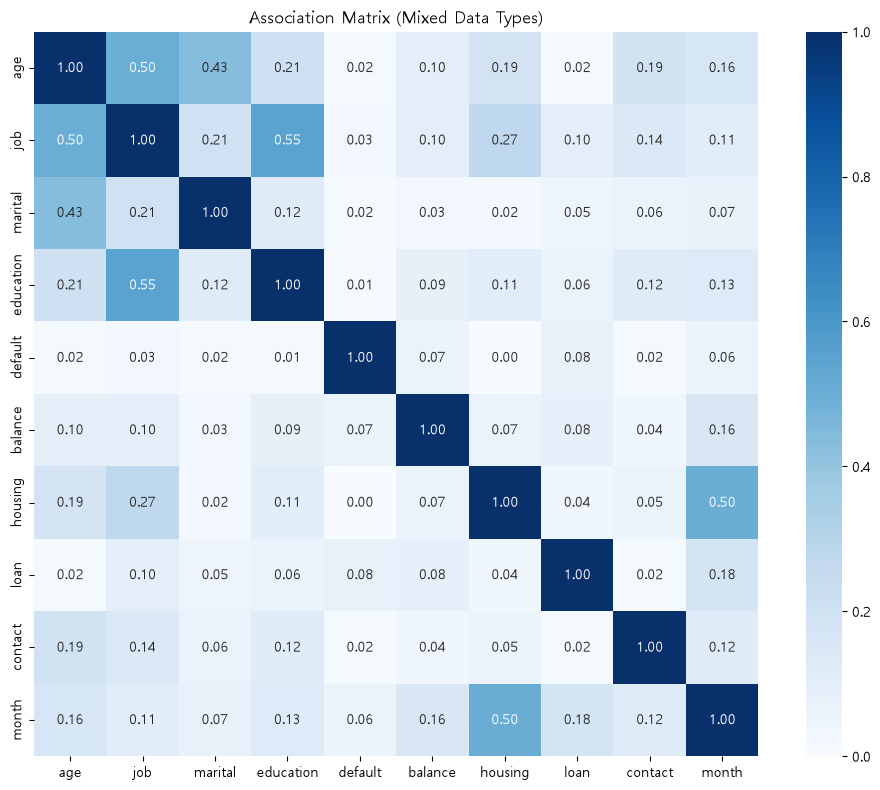

In [19]:
# 1. 분석할 변수
cols = [
    'age', 'job', 'marital', 'education',
    'default', 'balance', 'housing', 'loan','contact','month'
]

data = df[cols].copy()

num_cols = ['age', 'balance']
cat_cols = [col for col in cols if col not in num_cols]

# unknown은 실제 직업/학력 등을 나타내는 범주가 아니므로
# 연관성 계산에서는 결측값으로 처리
data[cat_cols] = data[cat_cols].replace('unknown', np.nan)


# 2. 범주형 ↔ 범주형: Cramér's V
def cramers_v(x, y):
    valid = pd.DataFrame({'x': x, 'y': y}).dropna()

    table = pd.crosstab(valid['x'], valid['y'])

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()

    # 편향 보정 Cramér's V
    phi2 = chi2 / n
    r, k = table.shape

    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1)**2 / (n - 1)
    k_corr = k - (k - 1)**2 / (n - 1)

    denom = min(k_corr - 1, r_corr - 1)

    return np.sqrt(phi2_corr / denom) if denom > 0 else np.nan


# 3. 범주형 ↔ 수치형: 상관비 (η)
def correlation_ratio(categories, values):
    valid = pd.DataFrame({
        'category': categories,
        'value': values
    }).dropna()

    if valid.empty:
        return np.nan

    overall_mean = valid['value'].mean()

    grouped = valid.groupby('category')['value']
    means = grouped.mean()
    counts = grouped.size()

    ss_between = (counts * (means - overall_mean)**2).sum()
    ss_total = ((valid['value'] - overall_mean)**2).sum()

    if ss_total == 0:
        return np.nan

    return np.sqrt(ss_between / ss_total)


# 4. 전체 연관성 행렬 생성
association = pd.DataFrame(
    np.eye(len(cols)),
    index=cols,
    columns=cols
)

for i, col1 in enumerate(cols):
    for j, col2 in enumerate(cols):
        if i >= j:
            continue

        if col1 in num_cols and col2 in num_cols:
            value = data[[col1, col2]].corr().iloc[0, 1]
            value = abs(value)

        elif col1 in cat_cols and col2 in cat_cols:
            value = cramers_v(data[col1], data[col2])

        elif col1 in cat_cols:
            value = correlation_ratio(data[col1], data[col2])

        else:
            value = correlation_ratio(data[col2], data[col1])

        association.loc[col1, col2] = value
        association.loc[col2, col1] = value


# 5. 히트맵 시각화
plt.figure(figsize=(10, 8))

sns.heatmap(
    association.astype(float),
    annot=True,
    fmt='.2f',
    cmap='Blues',
    vmin=0,
    vmax=1,
    square=True
)

plt.title('Association Matrix (Mixed Data Types)')
plt.tight_layout()
plt.show()

> job은  age랑 education 상관관게가 있고
> <br> education은 job이랑
> <br> contact는 다른 변수랑 상관관계가 크게 있어 보이지 x

In [20]:
pd.crosstab(
    df['month'],
    df['contact'],
    normalize='index'
).round(3)

contact,cellular,telephone,unknown
month,,,
apr,0.930,0.068,0.002
aug,0.952,0.039,0.008
dec,0.813,0.173,0.014
feb,0.892,0.103,0.005
jan,0.902,0.092,0.006
jul,0.836,0.124,0.040
jun,0.136,0.015,0.849
mar,0.874,0.111,0.015
may,0.387,0.033,0.579


[카이제곱 독립성 검정]
- 가설
- H₀: job과 education은 서로 독립이다.
- H₁: job과 education은 서로 독립이 아니다.


In [21]:
# unknown 제외
data_chi = df[
    (df['job'] != 'unknown') &
    (df['education'] != 'unknown')
]

# 교차표 생성
table = pd.crosstab(
    data_chi['job'],
    data_chi['education']
)

# 카이제곱 독립성 검정
chi2, p_value, dof, expected = chi2_contingency(table)

print(f"카이제곱 통계량: {chi2:.4f}")
print(f"p-value: {p_value:.6e}")
print(f"자유도: {dof}")
print(f"기대빈도 5 미만 셀 수: {(expected < 5).sum()}")

카이제곱 통계량: 26565.6590
p-value: 0.000000e+00
자유도: 20
기대빈도 5 미만 셀 수: 0


[일원분산분석(ANOVA)]
- 가설 설정
- H₀: 모든 직업군의 평균 나이는 같다.
- H₁: 적어도 하나의 직업군은 평균 나이가 다르다.

In [22]:
# job이 unknown인 데이터 제외
data_anova = df[df['job'] != 'unknown']

# 직업별 나이 데이터
groups = [
    group['age'].dropna().values
    for _, group in data_anova.groupby('job')
]

# ANOVA
f_stat, p_value = f_oneway(*groups)

print(f"F-statistic: {f_stat:.4f}")
print(f"p-value: {p_value:.6e}")

F-statistic: 1504.1207
p-value: 0.000000e+00


### 실험-> 어떤 방식으로 unknown 값 대체할 것인가

In [23]:
# ==================================================
# 1. 설명변수와 타깃변수 분리
# ==================================================

X = df.drop(columns=["duration", "y"]).copy()
y = df["y"].map({"no": 0, "yes": 1})

# unknown은 결측값으로 바꾸지 않고 문자열로 유지


# ==================================================
# 2. Train / Validation / Test 분리
#    Train 60% / Validation 20% / Test 20%
# ==================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# 각 데이터의 원본을 보관한다.
X_train_original = X_train.copy()
X_val_original = X_val.copy()
X_test_original = X_test.copy()



# ===============================================
# baseline 성능 측정
# =================================================

# 모델 학습시키기
baseline_model.fit(X_train_original,y_train)

# 예측하기
baseline_model.predict(X_val_original)

# validation 데이터로 평가하기
y_pred = baseline_model.predict(X_val_original)
y_prob = baseline_model.predict_proba(X_val_original)[:,1]

# 성능 지표 계산
baseline_result = {
    "Model": 'baseline model unknown 데이터 처리 안한 것',
    "PR-AUC": average_precision_score(y_val, y_prob),
    "F1": f1_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "Precision": precision_score(y_val, y_pred),
    "Accuracy": accuracy_score(y_val, y_pred),
}

# ==================================================
# 3. unknown 대체용 분류 모델 생성 함수
# ==================================================

# y값 예측하기 위한 모델이 아니라
# job이나 education 값을 예측하기 위한 모델
def make_imputation_model(numeric_cols, categorical_cols):

    transformers = []

    if numeric_cols:
        # 숫자형 변수의 스케일 조정
        transformers.append(
            ("num", StandardScaler(), numeric_cols)
        )

    if categorical_cols:
        transformers.append(
            (
                # 범주형 변수 모델이 처리할 수 있는 숫자 형태로 변환
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_cols
            )
        )

    preprocessor = ColumnTransformer(transformers)

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ])


# ==================================================
# 4. unknown 대체용 분류 모델 학습
#
# job: age + education -> job 예측
# education: job -> education 예측
#
# Train 데이터만 사용
# ==================================================

def fit_unknown_models(train_df):

    # job 예측 모델
    job_known = train_df["job"].ne("unknown")

    job_model = make_imputation_model(
        numeric_cols=["age"],
        categorical_cols=["education"]
    )

    job_model.fit(
        train_df.loc[
            job_known, ["age", "education"]
        ],
        train_df.loc[job_known, "job"]
    )

    # education 예측 모델
    edu_known = train_df["education"].ne("unknown")

    edu_model = make_imputation_model(
        numeric_cols=[],
        categorical_cols=["job"]
    )

    edu_model.fit(
        train_df.loc[edu_known, ["job"]],
        train_df.loc[edu_known, "education"]
    )

    return job_model, edu_model

In [26]:
# ==================================================
# 5. 조건별 최빈값 대체 규칙 학습
#
# job: education + age 구간별 최빈값
# education: job별 최빈값
#
# Train 데이터만 사용
# ==================================================

def fit_mode_rules(train_df):

    ref = train_df.copy()

    # 나이를 20세 미만/30대/40대/50대/60대 이상으로 구분
    ref["_age_bin"] = pd.cut(
        ref['age'],
        bins=[-float('inf'),29,39,49,59,float('inf')],
        labels=['20대 이하','30대','40대','50대','60대 이상']
    )

    # education별 job 최빈값
    job_by_edu = (
        # ne= not equal을 의미한다.
        ref.loc[ref["job"].ne("unknown")]
        .groupby("education")["job"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict() # 결과값 ex. 'tertiary':'management' -> dictionary 반환
    )

    # education + 나이 구간별 job 최빈값
    job_by_edu_age = (
        ref.loc[ref["job"].ne("unknown")]
        .groupby(["education", "_age_bin"])["job"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict()
    )

    # job별 education 최빈값
    edu_by_job = (
        ref.loc[ref["education"].ne("unknown")]
        .groupby("job")["education"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict()
    )

    return {
        "job_by_edu": job_by_edu,
        "job_by_edu_age": job_by_edu_age,
        "edu_by_job": edu_by_job,

        "job_global": ref.loc[
            ref["job"].ne("unknown"), "job"
        ].mode().iloc[0],

        "edu_global": ref.loc[
            ref["education"].ne("unknown"), "education"
        ].mode().iloc[0]
    }

In [27]:

def transform_unknown(data, job_model, edu_model, rules, method):

    result = data.copy()
    original = data.copy()

    job_mask = original["job"].eq("unknown")
    edu_mask = original["education"].eq("unknown")

    # 나이를 지정한 5개 구간으로 분류
    age_bins = [-float("inf"), 29, 39, 49, 59, float("inf")]
    age_labels = ["20대 이하", "30대", "40대", "50대", "60대 이상"]

    # ----------------------------------------------
    # job 대체 함수: 모델
    # ----------------------------------------------
    def replace_job_model():
        if job_mask.any():
            result.loc[job_mask, "job"] = job_model.predict(
                original.loc[job_mask, ["age", "education"]]
            )

    # ----------------------------------------------
    # job 대체 함수: 조건별 최빈값
    # ----------------------------------------------
    def replace_job_mode():
        for idx in original.index[job_mask]:

            edu = original.at[idx, "education"]
            age = original.at[idx, "age"]

            age_bin = pd.cut(
                pd.Series([age]),
                bins=age_bins,
                labels=age_labels
            ).iloc[0]

            # 1순위: education + 나이 구간별 최빈값
            # 2순위: education별 최빈값
            # 3순위: 전체 job 최빈값
            result.at[idx, "job"] = rules[
                "job_by_edu_age"
            ].get(
                (edu, age_bin),
                rules["job_by_edu"].get(
                    edu, rules["job_global"]
                )
            )

    # ----------------------------------------------
    # education 대체 함수: 모델
    # ----------------------------------------------
    def replace_education_model():
        if edu_mask.any():
            result.loc[edu_mask, "education"] = edu_model.predict(
                original.loc[edu_mask, ["job"]]
            )

    # ----------------------------------------------
    # education 대체 함수: 최빈값
    # ----------------------------------------------
    def replace_education_mode():
        for idx in original.index[edu_mask]:

            job = original.at[idx, "job"]

            result.at[idx, "education"] = rules[
                "edu_by_job"
            ].get(
                job, rules["edu_global"]
            )

    # ----------------------------------------------
    # 8가지 실험 방식
    # ----------------------------------------------

    if method == "model_both":
        replace_job_model()
        replace_education_model()

    elif method == "mode_both":
        replace_job_mode()
        replace_education_mode()

    elif method == "job_model_edu_mode":
        replace_job_model()
        replace_education_mode()

    elif method == "job_mode_edu_model":
        replace_job_mode()
        replace_education_model()

    elif method == "job_model_only":
        replace_job_model()

    elif method == "job_mode_only":
        replace_job_mode()

    elif method == "edu_model_only":
        replace_education_model()

    elif method == "edu_mode_only":
        replace_education_mode()

    else:
        raise ValueError(f"알 수 없는 처리 방식: {method}")

    return result


In [28]:


# ==================================================
# 7. 실험별 데이터 준비 함수
#
# Exp5, Exp6:
# job=unknown 행을 삭제한 후
# education unknown을 대체
# ==================================================

def prepare_experiment_data(
    X_data, y_data,
    job_model, edu_model, rules,
    method, drop_job_unknown=False
):

    X_exp = X_data.copy()
    y_exp = y_data.copy()

    # job=unknown 행 삭제
    if drop_job_unknown:

        keep_mask = X_exp["job"].ne("unknown")

        X_exp = X_exp.loc[keep_mask].copy()
        y_exp = y_exp.loc[keep_mask].copy()

    # education 또는 job unknown 대체
    X_exp = transform_unknown(
        X_exp,
        job_model,
        edu_model,
        rules,
        method
    )

    return X_exp, y_exp


# ==================================================
# 8. 대체 모델 및 최빈값 규칙 학습
# ==================================================

job_model, edu_model = fit_unknown_models(
    X_train_original
)

mode_rules = fit_mode_rules(
    X_train_original
)


In [29]:


# ==================================================
# 9. 6개 실험 정의
# ==================================================


experiments = [
    {
        "name": "Exp1_Model_Both",
        "method": "model_both"
    },
    {
        "name": "Exp2_Mode_Both",
        "method": "mode_both"
    },
    {
        "name": "Exp3_Job_Model_Edu_Mode",
        "method": "job_model_edu_mode"
    },
    {
        "name": "Exp4_Job_Mode_Edu_Model",
        "method": "job_mode_edu_model"
    },
    {
        "name": "Exp5_Job_Model_Only",
        "method": "job_model_only"
    },
    {
        "name": "Exp6_Job_Mode_Only",
        "method": "job_mode_only"
    },
    {
        "name": "Exp7_Edu_Model_Only",
        "method": "edu_model_only"
    },
    {
        "name": "Exp8_Edu_Mode_Only",
        "method": "edu_mode_only"
    }
]




In [30]:

# ==================================================
# 10. 8개 실험 실행 및 Validation 평가
# ==================================================

from sklearn.base import clone

results = []
fitted_models = {}
processed_data = {}

for config in experiments:

    experiment_name = config["name"]
    method = config["method"]

    # 현재 8개 실험에서는 job=unknown 행을 삭제하지 않음
    drop_job_unknown = False

    # ----------------------------------------------
    # 1. Train 데이터 전처리
    # ----------------------------------------------
    X_train_exp, y_train_exp = prepare_experiment_data(
        X_train_original,
        y_train,
        job_model,
        edu_model,
        mode_rules,
        method,
        drop_job_unknown
    )

    # ----------------------------------------------
    # 2. Validation 데이터 전처리
    # ----------------------------------------------
    X_val_exp, y_val_exp = prepare_experiment_data(
        X_val_original,
        y_val,
        job_model,
        edu_model,
        mode_rules,
        method,
        drop_job_unknown
    )

    # ----------------------------------------------
    # 3. Test 데이터 전처리
    # 최종 평가 전까지 성능 계산에는 사용하지 않음
    # ----------------------------------------------
    X_test_exp, y_test_exp = prepare_experiment_data(
        X_test_original,
        y_test,
        job_model,
        edu_model,
        mode_rules,
        method,
        drop_job_unknown
    )

    # ----------------------------------------------
    # 4. 실험별 예측 모델 생성 및 학습
    # ----------------------------------------------
    # 동일한 모델 구조를 사용하되,
    # 실험마다 새로운 모델 객체를 생성
    model = clone(baseline_model)

    model.fit(
        X_train_exp,
        y_train_exp
    )

    # ----------------------------------------------
    # 5. Validation 예측
    # ----------------------------------------------
    y_pred = model.predict(X_val_exp)

    y_prob = model.predict_proba(
        X_val_exp
    )[:, 1]

    # ----------------------------------------------
    # 6. Validation 성능 평가
    # ----------------------------------------------
    results.append({
        "Experiment": experiment_name,

        "Train_Size": len(X_train_exp),
        "Val_Size": len(X_val_exp),

        # Average Precision
        # PR-AUC의 대용 지표로 자주 사용
        "PR-AUC": average_precision_score(
        y_val_exp, y_prob
        ),

        "F1": f1_score(
            y_val_exp,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val_exp,
            y_pred,
            zero_division=0
        ),

        "Precision": precision_score(
            y_val_exp,
            y_pred,
            zero_division=0
        ),

        "Accuracy": accuracy_score(
            y_val_exp,
            y_pred
        ),

        "ROC-AUC": roc_auc_score(
            y_val_exp,
            y_prob
        )
    })

    # ----------------------------------------------
    # 7. 학습 모델 및 전처리 데이터 저장
    # ----------------------------------------------
    fitted_models[experiment_name] = model

    processed_data[experiment_name] = {
        "train": X_train_exp,
        "val": X_val_exp,
        "test": X_test_exp,

        "y_train": y_train_exp,
        "y_val": y_val_exp,
        "y_test": y_test_exp
    }

print(f"완료된 실험 수: {len(results)}")


완료된 실험 수: 8


In [31]:

# ==================================================
# 11. Baseline 및 실험 결과 비교
# ==================================================

# Baseline 결과를 DataFrame으로 변환
baseline_comparison = pd.DataFrame([baseline_result])

# 8개 실험 결과를 DataFrame으로 변환
experiment_comparison = pd.DataFrame(results)

# Baseline과 8개 실험 결과 합치기
comparison = pd.concat(
    [
        baseline_comparison.rename(
            columns={"Model": "Experiment"}
        ),
        experiment_comparison
    ],
    ignore_index=True
)

# 비교할 성능 지표만 선택
comparison = comparison[
    [
        "Experiment",
        "PR-AUC" if "PR-AUC" in comparison.columns else "AP",
        "F1",
        "Recall",
        "Precision",
        "Accuracy"
    ]
].copy()

# AP라는 이름으로 저장한 경우 PR-AUC로 표시
comparison = comparison.rename(
    columns={"AP": "PR-AUC"}
)

# 결과 출력
display(comparison.round(6))


,Experiment,PR-AUC,F1,Recall,Precision,Accuracy
0,baseline model unknown 데이터 처리 안한 것,0.405667,0.278405,0.174858,0.682657,0.893939
1,Exp1_Model_Both,0.405855,0.275602,0.172968,0.677778,0.893608
2,Exp2_Mode_Both,0.405882,0.276900,0.173913,0.678967,0.893718
3,Exp3_Job_Model_Edu_Mode,0.405855,0.275602,0.172968,0.677778,0.893608
4,Exp4_Job_Mode_Edu_Model,0.405882,0.276900,0.173913,0.678967,0.893718
5,Exp5_Job_Model_Only,0.405538,0.277108,0.173913,0.681481,0.893829
6,Exp6_Job_Mode_Only,0.405547,0.278405,0.174858,0.682657,0.893939
7,Exp7_Edu_Model_Only,0.405896,0.275810,0.172968,0.680297,0.893718
8,Exp8_Edu_Mode_Only,0.405896,0.275810,0.172968,0.680297,0.893718


### unknown 값 대체하지 않고 유지하기
* 성능차이가 크지 않음

* 전체 df 데이터셋 자체에다가 적용한것

In [32]:
# 수치형 데이터 통계량 확인하기
display(df.describe())


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


### Age
- 추후 파생변수 생성 필요

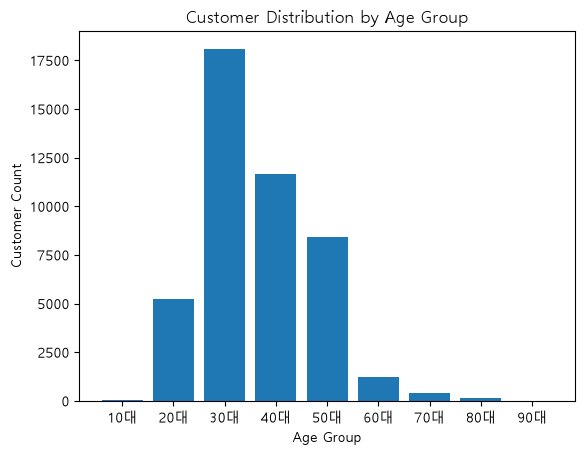

In [33]:
# age 연령대 그룹별 파생 변수 생성
df['age_group'] = (df['age']//10 *10).astype(int).astype(str) +'대'

# 연령대별 고객 수 막대그래프로 확인하기
age_count = df['age_group'].value_counts().sort_index()

plt.bar(age_count.index, age_count.values)
plt.xlabel('Age Group')
plt.ylabel('Customer Count')
plt.title('Customer Distribution by Age Group')
plt.show()

### balance
> 위의 통계치 확인했을 때 최소값은 약 -8019,  최대값은 102127 평균은 약 1362 -> 이상치 탐지가 필요함

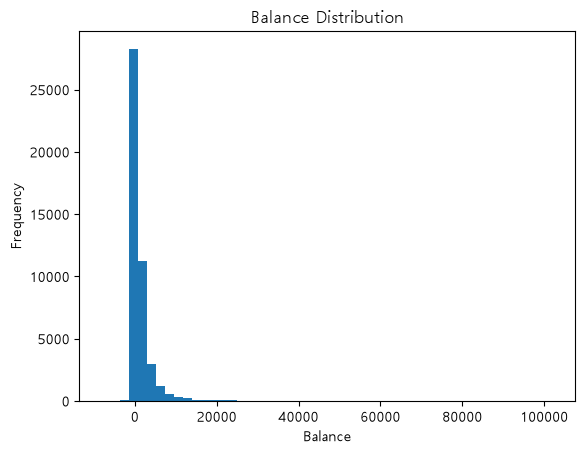

C:\Users\hasoo\AppData\Local\Temp\ipykernel_50392\3273713060.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['balance'].dropna(),vert=False)


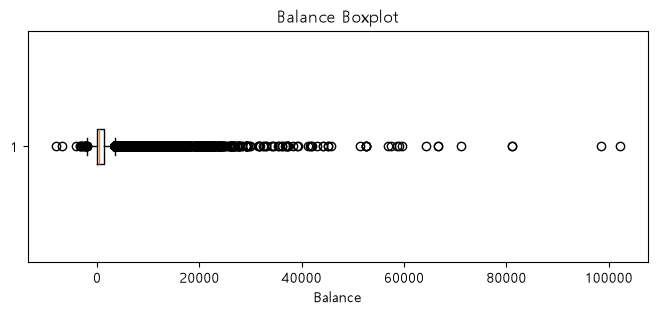

In [34]:
plt.Figure(figsize=(8,4))
plt.hist(df['balance'].dropna(),bins=50)
plt.xlabel('Balance')
plt.ylabel('Frequency')
plt.title('Balance Distribution')
plt.show()

plt.figure(figsize=(8,3))
plt.boxplot(df['balance'].dropna(),vert=False)
plt.xlabel('Balance')
plt.title('Balance Boxplot')
plt.show()

In [35]:
# IQR로 이상치 후보 확인하기
Q1 = df['balance'].quantile(0.25)
Q3 = df['balance'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5 * IQR

print(f'Q1: {Q1}')
print(f'Q3: {Q3}')
print(f'IQR: {IQR}')
print(f'하한: {lower}')
print(f'상한: {upper}')

outliers = df[(df['balance']<lower)|(df['balance']>upper)]

print(f'이상치 후보 개수: {len(outliers)}')
print(f'이상치 후보 비율: {len(outliers)/df['balance'].notna().sum()*100:.2f}%')


Q1: 72.0
Q3: 1428.0
IQR: 1356.0
하한: -1962.0
상한: 3462.0
이상치 후보 개수: 4729
이상치 후보 비율: 10.46%


In [36]:
# 후보들 실제 값 살펴보기
print(df['balance'].nsmallest(10))

# 가장 큰 잔액 10개
print(df['balance'].nlargest(10))

12909   -8019
15682   -6847
38736   -4057
7413    -3372
1896    -3313
32713   -3058
18573   -2827
31509   -2712
25119   -2604
14434   -2282
Name: balance, dtype: int64
39989    102127
26227     98417
42558     81204
43393     81204
41693     71188
19785     66721
21192     66653
19420     64343
41374     59649
12926     58932
Name: balance, dtype: int64


In [37]:
# 음수 잔액의 개수와 비율
negative_count = (df['balance'] < 0).sum()
valid_count = df['balance'].notna().sum()

print('음수 잔액 개수:', negative_count)
print(f'음수 잔액 비율: {negative_count / valid_count * 100:.2f}%')

음수 잔액 개수: 3766
음수 잔액 비율: 8.33%


>음수 잔액(마이너스 통장)이나 고액 잔액은 실제 금융 거래에서 발생할 수 있으므로 단순히 극단적인 값으로 오류 데이터로 판단하기 어려움
> 추후 모델링에서 대조 비교 (이상치 처리 or 처리 x 성능 비교)

### duration
> 모델 학습에 활용할 경우 데이터 누수가 발생할 수 있으므로 삭제

### campaign/pdays/previous  이상치 탐지

,Variable,Count,Q1,Q3,IQR,Lower,Upper,Outlier_Count,Outlier_Ratio(%)
0,campaign,45211,1.0,3.0,2.0,-2.0,6.0,3064,6.78
1,pdays,8257,133.0,327.0,194.0,-158.0,618.0,49,0.59
2,previous,8257,1.0,4.0,3.0,-3.5,8.5,453,5.49


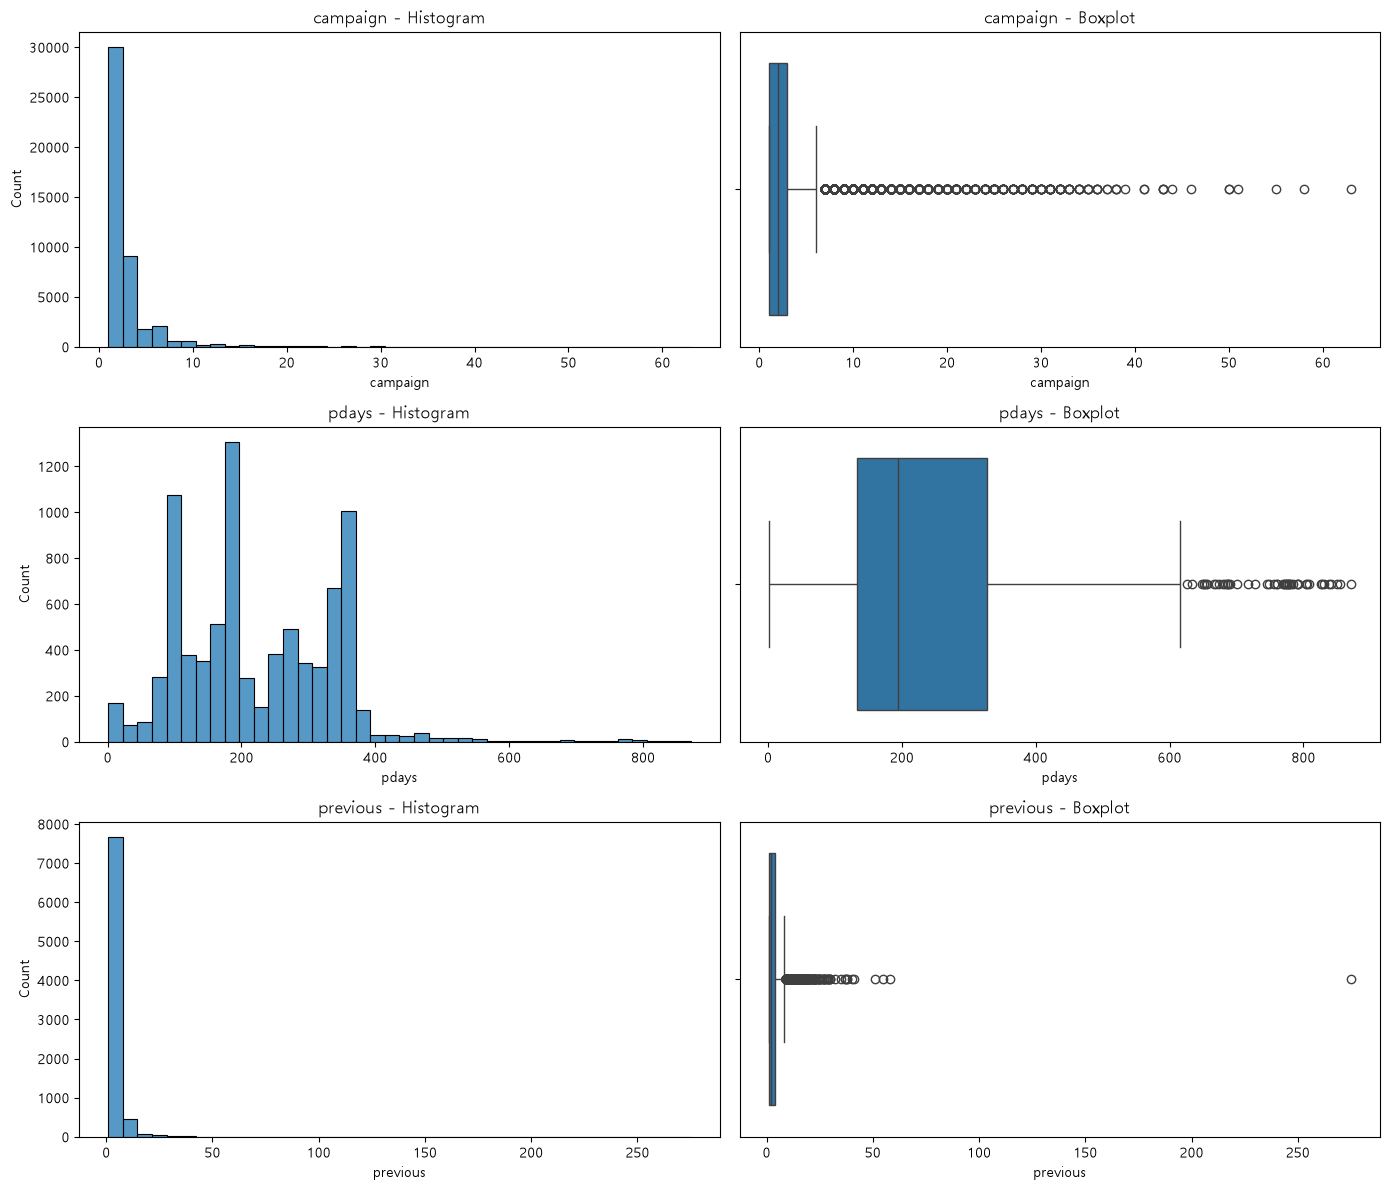


[campaign]
0.50     2.0
0.75     3.0
0.90     5.0
0.95     8.0
0.99    16.0
1.00    63.0
Name: campaign, dtype: float64

[pdays]
0.50    194.00
0.75    327.00
0.90    362.40
0.95    370.00
0.99    531.44
1.00    871.00
Name: pdays, dtype: float64

[previous]
0.50      2.0
0.75      4.0
0.90      6.0
0.95      9.0
0.99     17.0
1.00    275.0
Name: previous, dtype: float64


In [38]:

# ==================================================
# 1. 이상치 탐지 대상 변수
# ==================================================

outlier_cols = ["campaign", "pdays", "previous"]

# 전체 데이터 기준 이상치 탐색
outlier_df = df[outlier_cols].copy()


# ==================================================
# 2. IQR 이상치 탐지 함수
# ==================================================

def detect_outliers_iqr(data, col, exclude_value=None):

    series = data[col].dropna()

    # 특별한 의미가 있는 값은 IQR 계산에서 제외
    if exclude_value is not None:
        series = series[series != exclude_value]

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = series[
        (series < lower) | (series > upper)
    ]

    return {
        "Variable": col,
        "Count": len(series),
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower": lower,
        "Upper": upper,
        "Outlier_Count": len(outliers),
        "Outlier_Ratio(%)": (
            len(outliers) / len(series) * 100
            if len(series) > 0 else 0
        )
    }


# ==================================================
# 3. 변수별 IQR 이상치 탐지
# ==================================================

results = []

# campaign: 전체 값 기준
results.append(
    detect_outliers_iqr(
        outlier_df, "campaign"
    )
)

# pdays: -1은 이전 연락 이력이 없음을 나타내므로 제외
results.append(
    detect_outliers_iqr(
        outlier_df, "pdays", exclude_value=-1
    )
)

# previous: 0은 이전 캠페인 연락 횟수가 없음을 나타내므로 제외
results.append(
    detect_outliers_iqr(
        outlier_df, "previous", exclude_value=0
    )
)

outlier_summary = pd.DataFrame(results)

display(outlier_summary.round(2))


# ==================================================
# 4. 변수별 분포 시각화
# ==================================================

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for i, col in enumerate(outlier_cols):

    series = outlier_df[col].dropna()

    if col == "pdays":
        series = series[series != -1]

    elif col == "previous":
        series = series[series != 0]

    # 히스토그램
    sns.histplot(
        series,
        bins=40,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"{col} - Histogram")
    axes[i, 0].set_xlabel(col)

    # 박스플롯
    sns.boxplot(
        x=series,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"{col} - Boxplot")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()


# ==================================================
# 5. 상위 분위수 확인
# ==================================================

for col in outlier_cols:

    series = outlier_df[col].dropna()

    if col == "pdays":
        series = series[series != -1]

    elif col == "previous":
        series = series[series != 0]

    print(f"\n[{col}]")

    print(
        series.quantile([
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            1.00
        ])
    )


> 위 데이터 상으로 봤을 때 previous 데이터 매우 극단값이 보임

In [39]:
# previous 상위 20개 고유값과 빈도 확인
print(df["previous"].value_counts().sort_index().tail(20))

# previous가 가장 큰 고객 10명 확인
display(
    df.nlargest(10, "previous")[
        ["age", "job", "campaign", "pdays", "previous", "poutcome", "y"]
    ]
)

previous
21     4
22     6
23     8
24     5
25     4
26     2
27     5
28     2
29     4
30     3
32     1
35     1
37     2
38     2
40     1
41     1
51     1
55     1
58     1
275    1
Name: count, dtype: int64


,age,job,campaign,pdays,previous,poutcome,y
29182,40,management,2,262,275,other,no
38326,46,blue-collar,2,353,58,other,yes
44089,37,technician,3,776,55,failure,yes
28886,31,management,3,256,51,failure,no
44822,27,blue-collar,1,778,41,other,no
42611,35,technician,3,270,40,other,no
28498,49,management,2,248,38,failure,no
37567,39,management,15,261,38,failure,no
26668,51,entrepreneur,9,112,37,other,no
42422,27,student,6,95,37,other,no


In [40]:
# previous의 이상치 후보만 추출
previous_outliers = df[
    df["previous"] > 8.5
]

print("이상치 후보 수:", len(previous_outliers))
print("이상치 후보 최솟값:", previous_outliers["previous"].min())
print("이상치 후보 최댓값:", previous_outliers["previous"].max())

# 상위 극단값의 분포
display(
    previous_outliers["previous"]
    .describe(percentiles=[0.90, 0.95, 0.99])
)

이상치 후보 수: 453
이상치 후보 최솟값: 9
이상치 후보 최댓값: 275


count    453.000000
mean      14.452539
std       13.940156
min        9.000000
90%       22.000000
95%       27.000000
99%       40.480000
max      275.000000
Name: previous, dtype: float64

In [41]:
# previous = 0 제외
previous_nonzero = df.loc[df["previous"] > 0, "previous"]

# 클리핑 기준 후보 계산
p95 = previous_nonzero.quantile(0.95)
p99 = previous_nonzero.quantile(0.99)

print(f"95% 분위수: {p95}")
print(f"99% 분위수: {p99}")
print(f"최댓값: {previous_nonzero.max()}")

# P99 초과 데이터 개수
print(f"P99 초과 건수: {(df['previous'] > p99).sum()}")

95% 분위수: 9.0
99% 분위수: 17.0
최댓값: 275
P99 초과 건수: 80


In [42]:

 
# ==================================================
# 1. 클리핑 및 삭제 기준 계산 (Train 기준)
#    - 기준값은 반드시 train 데이터로만 계산
#      (validation까지 포함해 계산하면 평가 데이터 정보가 학습에 섞여 들어감)
#    - previous = 0은 "이전 캠페인 연락 없음"이라는 의미가 있는 값이고
#      전체의 약 82%를 차지함 → 포함하면 Q1, Q3가 모두 0이 되어 IQR = 0이 되고
#      1회 이상 연락한 고객이 전부 이상치로 잡힘 → 0을 제외하고 계산
# ==================================================
 
# previous > 0인 값만 추출 (이전 연락 이력이 있는 고객)
previous_nonzero = X_train_original.loc[
    X_train_original["previous"] > 0, "previous"
]
 
# P99 클리핑 상한값
#   - 상위 1%를 넘는 값은 이 값으로 고정
#   - previous는 연락 '횟수'라 정수 → np.ceil로 올려서 클리핑 후에도 정수가 유지되게 함
clip_upper = int(np.ceil(previous_nonzero.quantile(0.99)))
 
# IQR 삭제 기준
#   - Q1 - 1.5×IQR ~ Q3 + 1.5×IQR 밖의 값을 이상치로 판단
#   - previous는 하한이 음수로 계산되어 아래쪽 이상치는 없음 → 상한만 사용
Q1 = previous_nonzero.quantile(0.25)
Q3 = previous_nonzero.quantile(0.75)
IQR = Q3 - Q1
iqr_upper = Q3 + 1.5 * IQR
 
print(f"P99 클리핑 상한값: {clip_upper}")
print(f"IQR 삭제 상한값: {iqr_upper}")
 
 
# ==================================================
# 2. 네 가지 실험용 데이터 준비
#    - 모든 실험에서 validation은 같은 고객(원본 그대로 또는 같은 기준으로 변환)을 사용
#      → 평가 대상이 같아야 실험 간 성능을 공정하게 비교할 수 있음
#    - 원본이 바뀌지 않도록 모든 데이터는 .copy()로 복사해서 사용
# ==================================================
 
# --------------------------------------------------
# 실험 1: Baseline (원본 유지)
#   - 이상치를 아무것도 처리하지 않은 기준 성능
# --------------------------------------------------
X_train_base = X_train_original.copy()
X_val_base = X_val_original.copy()
y_train_base = y_train.copy()
y_val_base = y_val.copy()
 
# --------------------------------------------------
# 실험 2: P99 Clipping
#   - 상한값을 넘는 previous를 상한값으로 고정 (행은 삭제하지 않음)
#   - validation에도 같은 상한값(train 기준)을 적용
#     → 실제 서비스에서도 새로 들어오는 고객에게 같은 규칙을 적용하게 되므로
# --------------------------------------------------
X_train_clip = X_train_original.copy()
X_val_clip = X_val_original.copy()
 
X_train_clip["previous"] = X_train_clip["previous"].clip(upper=clip_upper)
X_val_clip["previous"] = X_val_clip["previous"].clip(upper=clip_upper)
 
y_train_clip = y_train.copy()
y_val_clip = y_val.copy()
 
# --------------------------------------------------
# 실험 3: IQR 기준 행 삭제
#   - previous가 IQR 상한값보다 큰 행을 train에서만 삭제
#   - validation은 원본 유지
#     → 실제로는 previous가 큰 고객도 예측해야 하므로 평가 데이터에서는 지우지 않음
#     → validation까지 지우면 실험마다 평가 대상이 달라져 비교가 불공정해짐
# --------------------------------------------------
train_keep = X_train_original["previous"] <= iqr_upper
 
X_train_delete = X_train_original.loc[train_keep].copy()
y_train_delete = y_train.loc[train_keep].copy()   # X와 같은 행을 남기도록 같은 조건 사용
 
X_val_delete = X_val_original.copy()
y_val_delete = y_val.copy()
 
# --------------------------------------------------
# 실험 4: previous 최댓값 행만 삭제 (train만)
#   - 극단적으로 큰 값 한두 건이 모델에 주는 영향만 따로 확인
#   - validation은 원본 유지 (실험 3과 같은 이유)
# --------------------------------------------------
previous_max = X_train_original["previous"].max()
train_keep_max = X_train_original["previous"] < previous_max
 
X_train_max_delete = X_train_original.loc[train_keep_max].copy()
y_train_max_delete = y_train.loc[train_keep_max].copy()
 
X_val_max_delete = X_val_original.copy()
y_val_max_delete = y_val.copy()
 
# 실험별 데이터 크기 확인 (validation 크기가 모두 같아야 정상)
print("\n[데이터 크기 비교]")
print("Baseline     Train/Val:", len(X_train_base), len(X_val_base))
print("Clipping     Train/Val:", len(X_train_clip), len(X_val_clip))
print("IQR Deletion Train/Val:", len(X_train_delete), len(X_val_delete))
print("Max Deletion Train/Val:", len(X_train_max_delete), len(X_val_max_delete))
print(f"\nIQR 삭제 행 수: {(~train_keep).sum()}")
print(f"previous 최댓값: {previous_max} | 삭제된 행 수: {(~train_keep_max).sum()}")
 
 
# ==================================================
# 3. 실험별 모델 학습 및 평가
#    - 네 실험 모두 baseline_model과 같은 설정의 '새 모델'을 복제해서 학습
#      (Baseline도 기존 학습 모델을 재사용하지 않고 같은 방식으로 새로 학습
#       → 학습 조건이 완전히 같다는 것이 보장됨)
#    - predict: 기본 임계값 0.5로 가입/미가입 예측 → F1, Recall, Precision, Accuracy 계산
#    - predict_proba: 가입 확률 → 임계값과 무관한 PR-AUC 계산
# ==================================================
 
experiment_data = {
    "Baseline_Original": (
        X_train_base, y_train_base, X_val_base, y_val_base
    ),
    "Previous_P99_Clipping": (
        X_train_clip, y_train_clip, X_val_clip, y_val_clip
    ),
    "Previous_IQR_Deletion": (
        X_train_delete, y_train_delete, X_val_delete, y_val_delete
    ),
    "Previous_Max_Deletion": (
        X_train_max_delete, y_train_max_delete, X_val_max_delete, y_val_max_delete
    ),
}
 
results_outlier = []      # 실험별 성능 지표 저장
outlier_models = {}       # 실험별 학습된 모델 저장 (나중에 계수 비교 등에 사용)
 
for name, (X_tr, y_tr, X_va, y_va) in experiment_data.items():
 
    # baseline_model과 같은 설정(전처리 + 로지스틱 회귀)의 빈 모델을 복제해서 새로 학습
    #   - clone: 학습 결과는 버리고 설정만 복사 → 기존 baseline_model은 그대로 유지됨
    #   - 네 실험 모두 같은 조건에서 학습되므로 공정한 비교 가능
    model = clone(baseline_model)
    model.fit(X_tr, y_tr)
 
    y_pred = model.predict(X_va)               # 0/1 예측
    y_prob = model.predict_proba(X_va)[:, 1]   # 가입(1) 확률
 
    results_outlier.append({
        "Experiment": name,
        "Train_Size": len(X_tr),
        "Val_Size": len(X_va),
        # PR-AUC: 불균형 데이터에서 가입자를 얼마나 잘 골라내는지 보는 핵심 지표
        "PR-AUC": average_precision_score(y_va, y_prob),
        # zero_division=0: 가입 예측이 하나도 없을 때 경고 대신 0으로 처리
        "F1": f1_score(y_va, y_pred, zero_division=0),
        "Recall": recall_score(y_va, y_pred, zero_division=0),
        "Precision": precision_score(y_va, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_va, y_pred),
    })
 
    outlier_models[name] = model
 
 
# ==================================================
# 4. 성능 비교
#    - 실험별 지표를 DataFrame으로 정리
#    - PR-AUC 기준 내림차순 정렬 (불균형 데이터에서 가장 중요하게 보는 지표)
# ==================================================
 
metrics = ["PR-AUC", "F1", "Recall", "Precision", "Accuracy"]
 
comparison_outlier = (
    pd.DataFrame(results_outlier)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)
 
display(
    comparison_outlier[["Experiment", *metrics, "Train_Size", "Val_Size"]].round(4)
)
 

P99 클리핑 상한값: 18
IQR 삭제 상한값: 8.5

[데이터 크기 비교]
Baseline     Train/Val: 27126 9042
Clipping     Train/Val: 27126 9042
IQR Deletion Train/Val: 26845 9042
Max Deletion Train/Val: 27125 9042

IQR 삭제 행 수: 281
previous 최댓값: 275 | 삭제된 행 수: 1


,Experiment,PR-AUC,F1,Recall,Precision,Accuracy,Train_Size,Val_Size
0,Previous_IQR_Deletion,0.4070,0.2812,0.1767,0.6875,0.8943,26845,9042
1,Previous_Max_Deletion,0.4065,0.2742,0.1711,0.6908,0.8940,27125,9042
2,Previous_P99_Clipping,0.4063,0.2742,0.1711,0.6908,0.8940,27126,9042
3,Baseline_Original,0.4057,0.2784,0.1749,0.6827,0.8939,27126,9042


* 역시 유의미 하지 않음 따라서 이상치 처리하지 x

### month/day 확인

In [43]:
# 원본 df에서 날짜 관련 컬럼 확인
print(df[["day", "month"]].dtypes)

print("\n월별 데이터 개수")
display(df["month"].value_counts().reindex([
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
], fill_value=0))

day      int64
month      str
dtype: object

월별 데이터 개수


month
jan     1403
feb     2649
mar      477
apr     2932
may    13766
jun     5341
jul     6895
aug     6247
sep      579
oct      738
nov     3970
dec      214
Name: count, dtype: int64

In [44]:
# ==========================================
# 원본 df 기준 날짜 데이터 유효성 통합 검사
# ==========================================

# 1. 월별 최대 일수
month_max_day = {
    "jan": 31, "feb": 29, "mar": 31, "apr": 30,
    "may": 31, "jun": 30, "jul": 31, "aug": 31,
    "sep": 30, "oct": 31, "nov": 30, "dec": 31
}

# 제공된 기간: May 2008 ~ November 2010
# 해당 기간에 등장할 수 있는 월의 종류
allowed_months = {
    "may", "jun", "jul", "aug", "sep", "oct", "nov",
    "dec", "jan", "feb", "mar", "apr"
}

# 원본 df의 날짜 컬럼만 복사하여 검사
date_check = df[["day", "month"]].copy()

# 검사에 사용할 월 값 정리 (원본 df는 변경하지 않음)
date_check["month_check"] = (
    date_check["month"].astype("string").str.strip().str.lower()
)

# 월별 최대 일수 매핑
date_check["max_day"] = date_check["month_check"].map(month_max_day)

# ① day가 1~31 범위를 벗어나는지
date_check["invalid_day_range"] = (
    date_check["day"].isna()
    | (date_check["day"] < 1)
    | (date_check["day"] > 31)
)

# ② 해당 월의 최대 일수를 초과하는지
date_check["invalid_month_day"] = (
    date_check["max_day"].isna()
    | date_check["day"].isna()
    | (date_check["day"] < 1)
    | (date_check["day"] > date_check["max_day"])
)

# ③ 월 값이 유효한지
date_check["invalid_month"] = ~date_check["month_check"].isin(month_max_day)

# ④ 제공된 기간에 등장할 수 있는 월인지
date_check["outside_month_range"] = ~date_check["month_check"].isin(allowed_months)

# 검사 결과 요약
summary = pd.DataFrame({
    "검사 항목": [
        "day가 1~31 범위를 벗어남",
        "월별 최대 일수를 초과함",
        "유효하지 않은 month 값",
        "제공된 기간의 월 범위에 포함되지 않음"
    ],
    "위반 행 수": [
        date_check["invalid_day_range"].sum(),
        date_check["invalid_month_day"].sum(),
        date_check["invalid_month"].sum(),
        date_check["outside_month_range"].sum()
    ]
})

display(summary)

# 하나라도 위반한 행을 한 번에 확인
invalid_mask = (
    date_check["invalid_day_range"]
    | date_check["invalid_month_day"]
    | date_check["invalid_month"]
    | date_check["outside_month_range"]
)

invalid_rows = df.loc[invalid_mask].copy()

print(f"전체 데이터: {len(df):,}행")
print(f"하나 이상의 검사 기준을 위반한 행: {len(invalid_rows):,}행")

display(invalid_rows)

,검사 항목,위반 행 수
0,day가 1~31 범위를 벗어남,0
1,월별 최대 일수를 초과함,0
2,유효하지 않은 month 값,0
3,제공된 기간의 월 범위에 포함되지 않음,0


전체 데이터: 45,211행
하나 이상의 검사 기준을 위반한 행: 0행


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,age_group


# feature engineering

In [45]:
data = df.copy()
data['y_bin'] = (data['y'] == 'yes').astype(int)
base_rate = data['y_bin'].mean()


# ① 10분위로 나눠 구간별 가입률 확인 (y와 무관하게 분포 기준으로 분할)
def decile_rate(col, q=10):
    bins = pd.qcut(data[col], q=q, duplicates='drop')
    g = data.groupby(bins, observed=True)['y_bin'].agg(['mean', 'size'])
    g['lift'] = g['mean'] / base_rate
    return g


# ② 단일 변수 결정트리로 가입률이 가장 크게 갈리는 경계값 탐색
#    - min_leaf: 한 구간이 전체에서 차지하는 최소 비율 (표본 작은 구간 방지)
def tree_bins(col, max_depth=3, min_leaf=0.05):
    m = DecisionTreeClassifier(max_depth=max_depth,
                               min_samples_leaf=min_leaf,
                               random_state=0)
    m.fit(data[[col]], data['y_bin'])
    t = m.tree_.threshold
    return sorted(round(float(x), 1) for x in t[t != -2])   # -2는 리프 노드 표시값


# IV 계산 (구간 후보 비교용)
def information_value(bins):
    table = pd.crosstab(bins, data['y_bin']) + 0.5        # 0 나눗셈 방지 스무딩
    dist = table / table.sum()
    return ((dist[1] - dist[0]) * np.log(dist[1] / dist[0])).sum()


# 지정한 구간으로 가입률·lift·표본 수·IV 계산
def rate_by_bins(col, bins, labels):
    s = pd.cut(data[col], bins=bins, labels=labels)
    g = data.groupby(s, observed=True)['y_bin'].agg(['mean', 'size'])
    g['lift'] = g['mean'] / base_rate
    return g, information_value(s)


# ==================================================
# age
# ==================================================

# ①② 패턴과 경계값 확인
print('\n=== age: 10분위별 가입률 ===')
print(decile_rate('age').round(3))

# min_leaf=0.05에서는 60세 이상(3.9%)이 한 구간이 될 수 없어 경계가 58.5로 밀림
# → 0.03으로 완화하면 59.5가 나와 실제 경계가 60세임을 확인
for ml in [0.05, 0.03]:
    print(f'age 결정트리 경계값 (min_leaf={ml}):',
          tree_bins('age', max_depth=4, min_leaf=ml))

# ③ 해석이 쉬운 연령대 기준으로 후보 구간 비교
age_candidates = {
    '연령대 6구간': (
        [-np.inf, 29, 39, 49, 59, 69, np.inf],
        ['20대 이하', '30대', '40대', '50대', '60대', '70대 이상']
    ),
    '연령대 5구간 (최종)': (
        [-np.inf, 29, 39, 49, 59, np.inf],
        ['20대 이하', '30대', '40대', '50대', '60대 이상']
    ),
    '연령대 4구간': (
        [-np.inf, 29, 39, 49, np.inf],
        ['20대 이하', '30대', '40대', '50대 이상']
    ),
}

for name, (bins, labels) in age_candidates.items():
    g, iv = rate_by_bins('age', bins, labels)
    print(f'\n--- {name} | IV = {iv:.3f} ---')
    print(g.round(3))

# ④ 최종 구간 확정
#   - 6구간: IV 0.183으로 가장 높지만 70대 이상 554명(test 105명)으로 값이 흔들림
#   - 5구간: IV 0.178로 거의 동일하면서 모든 구간 표본이 충분 → 채택
#   - 4구간: 50대(9.3%)와 60대 이상(33.6%)이 섞여 IV 0.062로 급감
AGE_BINS = [-np.inf, 29, 39, 49, 59, np.inf]
AGE_LABELS = ['20대 이하', '30대', '40대', '50대', '60대 이상']
data['age_group'] = pd.cut(data['age'], bins=AGE_BINS, labels=AGE_LABELS)


# ==================================================
# balance
# ==================================================

print('\n=== balance: 10분위별 가입률 ===')
print(decile_rate('balance').round(3))
print('balance 결정트리 경계값:', tree_bins('balance', max_depth=3))


# ==================================================
# month: 범주형이라 월별 가입률을 보고 비슷한 수준끼리 묶음
# ==================================================

month_rate = data.groupby('month')['y_bin'].agg(['mean', 'size'])
month_rate['lift'] = month_rate['mean'] / base_rate
print('\n=== month별 가입률 ===')
print(month_rate.sort_values('mean', ascending=False).round(3))


=== age: 10분위별 가입률 ===
                 mean  size   lift
age                               
(17.999, 29.0]  0.176  5273  1.504
(29.0, 32.0]    0.110  5838  0.943
(32.0, 34.0]    0.105  3902  0.894
(34.0, 36.0]    0.109  3700  0.933
(36.0, 39.0]    0.098  4649  0.840
(39.0, 42.0]    0.089  3888  0.763
(42.0, 46.0]    0.090  4688  0.766
(46.0, 51.0]    0.090  4954  0.768
(51.0, 56.0]    0.095  4197  0.811
(56.0, 95.0]    0.203  4122  1.738
age 결정트리 경계값 (min_leaf=0.05): [29.5, 31.5, 37.5, 39.5, 58.5]
age 결정트리 경계값 (min_leaf=0.03): [26.5, 29.5, 30.5, 36.5, 57.5, 59.5]

--- 연령대 6구간 | IV = 0.183 ---
         mean   size   lift
age                        
20대 이하  0.176   5273  1.504
30대     0.106  18089  0.904
40대     0.091  11655  0.780
50대     0.093   8410  0.798
60대     0.297   1230  2.537
70대 이상  0.424    554  3.626

--- 연령대 5구간 (최종) | IV = 0.178 ---
         mean   size   lift
age                        
20대 이하  0.176   5273  1.504
30대     0.106  18089  0.904
40대     0.091  11655  0.780

* 10분위·트리에서 30세 미만과 60세 이상만 높은 U자형 확인(트리 경계 29.5·59.5). 10살 단위는 10대 47명·90대 9명 등 표본이 작아 가입률이 불안정 → 6구간(IV 0.183)·5구간(0.178)·4구간(0.062) 비교 후 20대 이하 / 30대 / 40대 / 50대 / 60대 이상 채택
* 트리 경계 중 0 부근, 798.5, 1,578.5를 사용 → 0 이하 / ~800 / ~1,580 / 1,580 초과
* 40% 이상 / 15~20% / 10% 안팎 / 5월(최저) 4개 그룹
* 별도 구간화 없음

In [47]:
# 분석할 변수 준비
# 나이, 잔액, 연락 횟수처럼 숫자 측정하는 변수
num_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

# category 변수
base_cat_cols = [
    'job', 'marital', 'education', 'default',
    'housing', 'loan', 'contact', 'month', 'poutcome'
]

# target 변수
target_col = 'y'

cols = num_cols + base_cat_cols + [target_col]
data = df[cols].copy()

In [48]:
# df에서 분석에 필요한 열만 선택하고 복사본 만들기
data = df[cols].copy()

In [50]:
# 이전 연락 이력 여부 생성하기
data['has_previous_contact'] = np.where(
    # pdays가 -1일때 참이면 no 값을 false면 yes값
    data['pdays'] == -1, 0, 1
)
cat_cols = base_cat_cols + ['has_previous_contact']

In [51]:
# pdays 값 -1 실제 경과 일수로 해석하지 않게 NaN으로 바꾸기
data['pdays'] = data['pdays'].replace(-1, np.nan)

In [52]:
# 타깃 0과 1로 변환하기
data['y_bin'] = (data[target_col] == 'yes').astype(int)

In [ ]:
# 연관성 행렬에 포함할 변수를 모으기
all_cols = num_cols + cat_cols + [target_col]

In [54]:
# 범주형 변수끼리 관계 확인하기: Cramer's V
def cramers_v(x, y):
    # 두 변수 데이터프레임으로 묶고 결측값인 행은 제외하기
    valid = pd.DataFrame({'x': x, 'y': y}).dropna()
    # pd.crosstab은 두 범주의 조합별 데이터 개수를 세는 교차표 
    table = pd.crosstab(valid['x'], valid['y'])

    # 계산할 수 있는 데이터인가
    if min(table.shape) < 2 :
        return np.nan

    # 카이제곱 통계량은 관측된 범주 조합별 빈도와 두 변수가 독립적이라고 가정했을 때의 기대 빈도 사이의  차이를 말함
    chi2 = chi2_contingency(table, correction=False)[0]
    n=table.to_numpy().sum()
    if n <= 1:
        return np.nan

    phi2 = chi2/n
    # r= 교차표 행 수 / k= 교차표의 열 수
    r, k = table.shape

    # 편향 보정 항목 phi2_corr, r_corr, k_corr
    phi2_corr = max(
        0,
        phi2 - (k-1)*(r-1)/(n-1)
    )

    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)

    denom = min(k_corr - 1, r_corr - 1)
    if denom <= 0:
        return np.nan

    return np.sqrt(phi2_corr/denom)

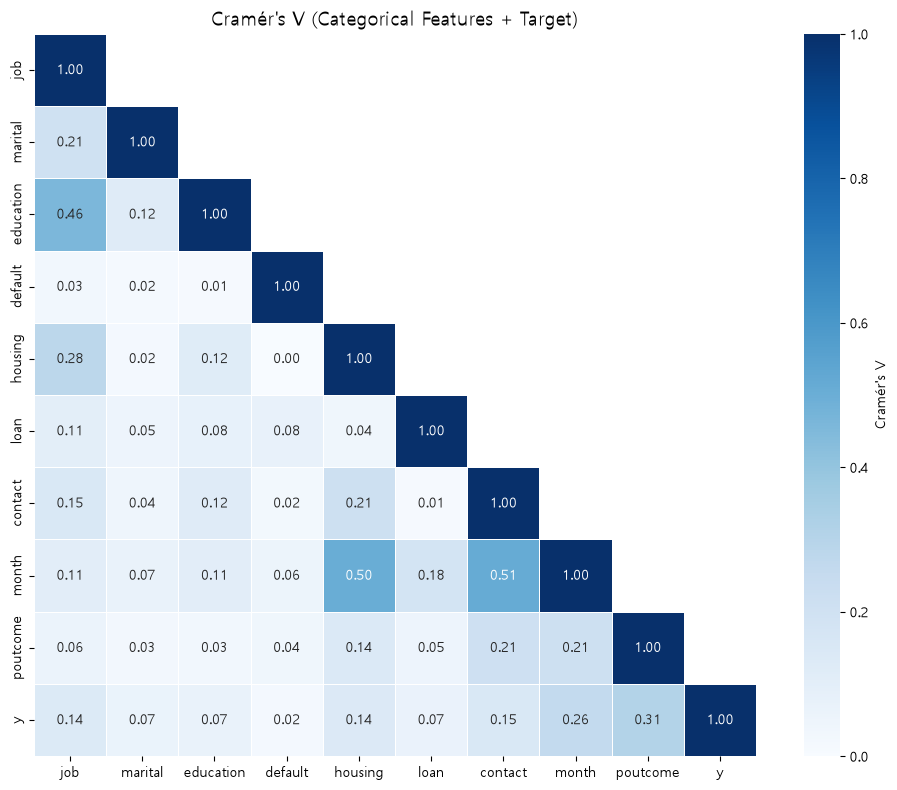

In [56]:
# 시각화하기
# ==================================================
# 범주형 변수 간 Cramér's V 행렬 계산
# ==================================================

# 분석할 범주형 변수 + 타깃(y)
#   - y도 yes/no 범주형이라 같은 방식으로 다른 변수와의 연관성을 볼 수 있음
cat_cols = ['job', 'marital', 'education', 'default', 'housing',
            'loan', 'contact', 'month', 'poutcome', 'y']

# 대각선(자기 자신과의 관계)은 1로 채운 빈 행렬
cv_matrix = pd.DataFrame(np.eye(len(cat_cols)), index=cat_cols, columns=cat_cols)

# 모든 변수 쌍에 대해 계산
#   - Cramér's V는 대칭(A↔B = B↔A)이라 위쪽 절반만 계산하고 아래쪽에 복사
for i, col1 in enumerate(cat_cols):
    for j, col2 in enumerate(cat_cols):
        if i < j:
            value = cramers_v(df[col1], df[col2])
            cv_matrix.loc[col1, col2] = value
            cv_matrix.loc[col2, col1] = value


# ==================================================
# 히트맵 시각화
# ==================================================

# 대칭 행렬이라 위쪽 절반은 가려서 같은 값이 두 번 보이지 않게 함
mask = np.triu(np.ones_like(cv_matrix, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cv_matrix.astype(float),
    mask=mask,
    annot=True, fmt='.2f',          # 칸마다 값 표시 (소수점 둘째 자리)
    cmap='Blues',
    vmin=0, vmax=1,                 # Cramér's V 범위 0~1로 색 고정
    square=True, linewidths=0.5,
    cbar_kws={'label': "Cramér's V"}
)
plt.title("Cramér's V (Categorical Features + Target)", fontsize=14)
plt.tight_layout()
plt.show()


- 변수끼리 연관이 가장 강한 쌍은 month와 contact(0.51), month와 housing(0.50), job과 education(0.46)
- month가 contact·housing과 강하게 엮인 건 캠페인이 특정 달에 특정 연락 방식과 고객층에 집중됐다는 뜻
- y와의 연관은 poutcome(0.31) > month(0.26) > contact(0.15) > housing(0.14) ≈ job(0.14) 순이고, default(0.02)는 거의 관계가 없다

In [58]:
# 범주형 변수와 수치형 변수의 관계: 상관비 
# categories는 범주형 변수, values는 수치형 변수
# ex. 범주형 변수: job, 수치형 변수: balance -> 직업별 잔액 평균이 얼마나 차이  나는지를 바탕으로 연관성을 측정한다.
def correlation_ratio(categories, values):
    valid = pd.DataFrame({
        'category': categories,
        'value': values
    }).dropna()

    if valid.empty or valid['category'].nunique() < 2:
        return np.nan

    # 전체 평균과 범주별 평균 계산
    # ex. 각 직업의 평균이 전체 평균에서 얼마나 떨어져 있는지, 전체 데이터의 변동이  얼마나 큰지를 이용함
    overall_mean = valid['value'].mean()
    grouped = valid.groupby('category')['value']
    means = grouped.mean()
    counts = grouped.size()

    # 집단 간 차이와 전체  차이 계산
    # 집단별 평균 차이가 전체 변동에서 차지하는 비중이 클수록 상관비가 커진다.
    # 즉, 상관비가 높으면 범주에 따라 수치형 변수의 평균이 달라지는 경향이 있다.
    ss_between = (counts * (means - overall_mean) ** 2).sum()
    ss_total = ((valid['value'] - overall_mean) ** 2).sum()

    if ss_total == 0:
        return np.nan

    return np.sqrt(ss_between / ss_total)

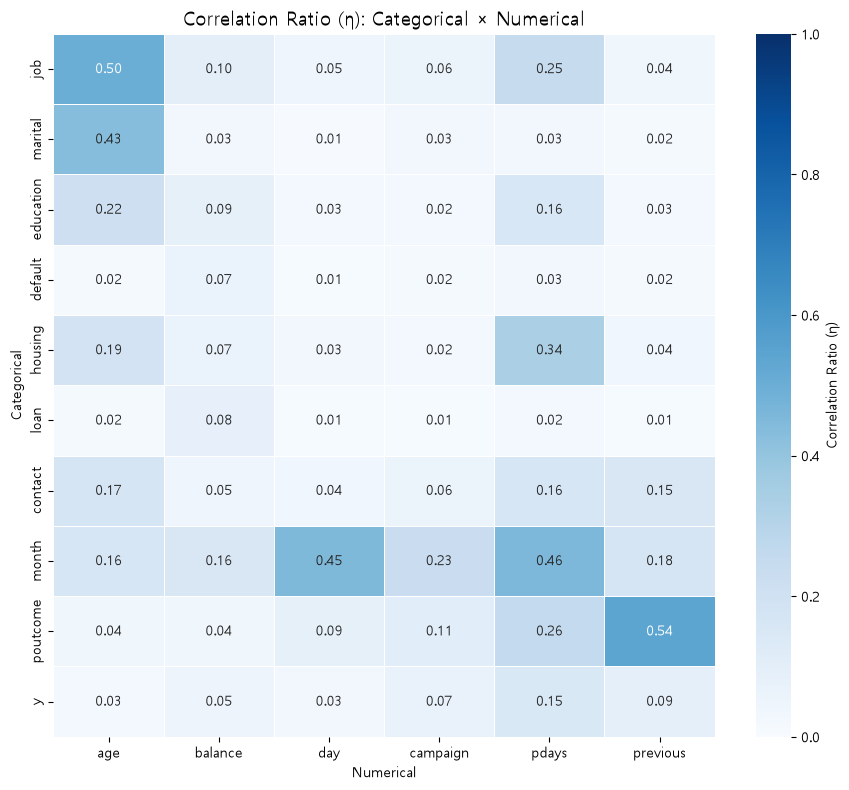

In [59]:
# ==================================================
# 범주형 × 수치형 상관비(η) 행렬 계산
# ==================================================

# 행: 범주형 변수 (+ 타깃 y), 열: 수치형 변수
#   - 상관비는 "범주에 따라 수치형 평균이 달라지는가"를 보는 지표라
#     범주형-범주형, 수치형-수치형 칸은 없음 → 정사각형이 아닌 직사각형 행렬
cat_cols = ['job', 'marital', 'education', 'default', 'housing',
            'loan', 'contact', 'month', 'poutcome', 'y']
num_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

eta_data = df[cat_cols + num_cols].copy()

# pdays = -1은 "이전 연락 없음"을 뜻하는 코드값이지 실제 경과 일수가 아님
#   → 그대로 두면 평균이 -1 쪽으로 크게 끌려가 왜곡되므로 계산에서만 제외(NaN)
#   → 함수 안의 dropna()로 자동 제외됨
eta_data['pdays'] = eta_data['pdays'].replace(-1, np.nan)

eta_matrix = pd.DataFrame(index=cat_cols, columns=num_cols, dtype=float)

for cat in cat_cols:
    for num in num_cols:
        eta_matrix.loc[cat, num] = correlation_ratio(eta_data[cat], eta_data[num])


# ==================================================
# 히트맵 시각화
# ==================================================

plt.figure(figsize=(9, 8))
sns.heatmap(
    eta_matrix,
    annot=True, fmt='.2f',          # 칸마다 값 표시
    cmap='Blues',
    vmin=0, vmax=1,                 # 상관비 범위 0~1로 색 고정
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Ratio (η)'}
)
plt.title('Correlation Ratio (η): Categorical × Numerical', fontsize=14)
plt.xlabel('Numerical')
plt.ylabel('Categorical')
plt.tight_layout()
plt.show()

- 연관이 강한 쌍은 poutcome-previous(0.54), job-age(0.50), month-pdays(0.46), month-day(0.45), marital-age(0.43)
- month-day는 캠페인이 특정 달의 특정 날짜에 몰려서 진행된다.는 가설을 세울 수 있음

In [60]:
# 수치형 변수 계산하기 : Spearman 상관계수- Pearson은 값의 크기를 그대로 써서 balance, campaign, previous처럼 꼬리가 긴 분포에서는 소수의 극단값에 결과가 크게 흔들린다.
# Spearman은 값을 순위로 바꿔서 계산해서 극단값 영향이 작고, 직선이 아니어도 '한쪽이 커지면 다른 쪽도 커지는(작아지는)' 단조 관계를 잡아낸다.
num_cols = ['age','balance','day','campaign','pdays','previous']
num_data = df[num_cols].copy()

# pdays=-1은 순위 계산에서 왜곡 될 수 있으므로 계산에서 제외
num_data['pdays'] = num_data['pdays'].replace(-1,np.nan)

# 상관계수 행렬 (부호 포함)
spearman_corr = num_data.corr(method='spearman')



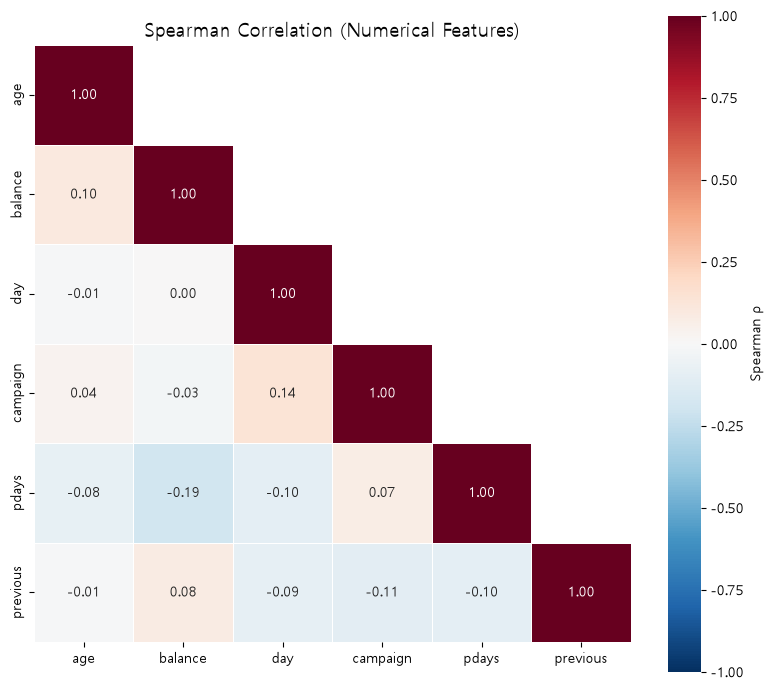

In [61]:
# 히트맵 시각화하기
mask = np.triu(np.ones_like(spearman_corr, dtype=bool), k=1)

plt.figure(figsize=(8, 7))
sns.heatmap(
    spearman_corr,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdBu_r',                  # 양수 빨강, 음수 파랑 → 방향을 색으로 구분
    vmin=-1, vmax=1, center=0,      # 0을 흰색으로 고정
    square=True, linewidths=0.5,
    cbar_kws={'label': 'Spearman ρ'}
)
plt.title('Spearman Correlation (Numerical Features)', fontsize=14)
plt.tight_layout()
plt.show()

* 수치형 변수끼리 상관관계는 매우 약하다

### 발견한 연관성을 기준으로 가설 세우고 검증하기
1. month가 contact와 housing과 강하게 엮여있음 
- 가설: 캠페인이 특정 달에 특정 연락 방식과 고객층에 집중되었을 것이다.
- 데이터셋 출처에  ordered by date (older version of this dataset with less inputs).  적혀 있음 따라서 데이터는 순서대로 구성되어 있음

In [71]:
# 확실히 순서대로 되어 있는게 맞는지 확인
# ==================================================
# month가 행 순서대로 이어져 있는지 확인
#   - 같은 달이 연속된 덩어리(run)를 찾아 순서대로 나열
#   - 월이 앞으로만 진행하다가 12월 → 1월처럼 되돌아가는 지점이 있다면
#     그곳이 연도가 바뀌는 지점
# ==================================================

# 이전 행과 month가 다르면 True → 누적합으로 덩어리 번호 부여
#   예: may, may, jun, jun, jul → 1, 1, 2, 2, 3
run_id = (df['month'] != df['month'].shift()).cumsum()

# 덩어리별 월, 시작 행, 끝 행, 건수
month_runs = (
    df.reset_index()
      .groupby(run_id.values)
      .agg(
          month=('month', 'first'),
          start_row=('index', 'first'),
          end_row=('index', 'last'),
          count=('month', 'size'),
      )
)

print(f'월 덩어리 개수: {len(month_runs)}')
display(month_runs)

월 덩어리 개수: 30


,month,start_row,end_row,count
1,may,0,7956,7957
2,jun,7957,12442,4486
3,jul,12443,18822,6380
4,aug,18823,24037,5215
5,oct,24038,24117,80
6,nov,24118,27715,3598
7,dec,27716,27728,13
8,jan,27729,28904,1176
9,feb,28905,31200,2296
10,mar,31201,31458,258


### 되돌아가는 행 없이 이어지고 있는것을 알 수 있음

In [65]:
# 월 이름 → 숫자 (1~12)
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun',
               'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_num = df['month'].map({m: i + 1 for i, m in enumerate(month_order)})

In [67]:
# 데이터가 날짜 순으로 정렬돼 있으므로,
# 이전 행보다 월 숫자가 작아지는 지점(예: 12월 → 1월)을 연도가 바뀌는 지점으로 봄
#   - cumsum(): 연도가 바뀔 때마다 1씩 누적 → 0, 1, 2
#   - 데이터 셋 설명상 시작이 2008년 5월이므로 2008을 더함
df['year'] = 2008 + (month_num < month_num.shift()).cumsum()

In [68]:
# 확인: 연도별 시작/끝 월과 건수
display(df.groupby('year')['month'].agg(['first', 'last', 'size']))

,first,last,size
year,,,
2008,may,dec,27729
2009,jan,dec,14862
2010,jan,nov,2620


In [69]:
# 연도별 가입률
y_bin = (df['y'] == 'yes').astype(int)
display(y_bin.groupby(df['year']).agg(['mean', 'size']).round(3))

,mean,size
year,,
2008,0.051,27729
2009,0.171,14862
2010,0.516,2620


#### 2008년에는 데이터 크기가 크지만 가입률은 낮음

In [70]:
# 연도 × 월 가입률
display(pd.crosstab(df['month'], df['year'], values=y_bin, aggfunc='mean')
        .reindex(month_order).round(3))

year,2008,2009,2010
month,,,
jan,NaN,0.032,0.458
feb,NaN,0.111,0.527
mar,NaN,0.484,0.562
apr,NaN,0.166,0.589
may,0.032,0.096,0.573
jun,0.045,0.375,0.488
jul,0.060,0.367,0.542
aug,0.055,0.342,0.523
sep,NaN,0.436,0.492


#### 특정 가입률이 높은 달을 확인하기 어렵다
#### 연도에 따라 가입률이 다름

캠페인 연락 횟수가 높을 수록 가입률이 높을 것이다.
<br>현재 캠페인 연락 횟수 -> y
<br>이전 캠페인 연락 횟수 -> 이전 마케팅 캠페인 결과


In [74]:
y_bin = (df['y'] == 'yes').astype(int)

# ==================================================
# 1. 현재 캠페인 연락 횟수(campaign) → 가입률(y)
# ==================================================
campaign_bin = pd.cut(
    df['campaign'],
    bins=[0, 1, 2, 3, 4, 5, 10, np.inf],
    labels=['1회', '2회', '3회', '4회', '5회', '6~10회', '11회 이상']
)

campaign_rate = y_bin.groupby(campaign_bin, observed=True).agg(가입률='mean', 건수='size')
display(campaign_rate.round(3))




,가입률,건수
campaign,,
1회,0.146,17544
2회,0.112,12505
3회,0.112,5521
4회,0.090,3522
5회,0.079,1764
6~10회,0.065,3159
11회 이상,0.039,1196


In [77]:
y_bin = (df['y'] == 'yes').astype(int)
repeat = df['campaign'] >= 4

print(f'4회 이상 고객 수: {repeat.sum():,}')
print(f'4회 이상 가입자 수: {y_bin[repeat].sum():,}')
print(f'4회 이상 가입률: {y_bin[repeat].mean():.3f}')
print(f'전체 가입률 대비: {y_bin[repeat].mean() / y_bin.mean():.2f}배')

# 전체 평균 가입률
y_bin = (df['y'] == 'yes').astype(int)

print(f'전체 고객 수: {len(df):,}')
print(f'전체 가입자 수: {y_bin.sum():,}')
print(f'전체 평균 가입률: {y_bin.mean():.3f}')

4회 이상 고객 수: 9,641
4회 이상 가입자 수: 709
4회 이상 가입률: 0.074
전체 가입률 대비: 0.63배
전체 고객 수: 45,211
전체 가입자 수: 5,289
전체 평균 가입률: 0.117


4회 이상 연락한 고객의 가입률은 7.4%로 평균의 0.6배 수준이므로, 3회 연락 후 반응이 없는 고객은 우선순위를 낮추는 연락 횟수 상한 정책을 제안한다
-> 연락 비용 관점에서 좋지 않음


#### 4회 이상 연락한 고객의 가입률은 7.4% 


In [75]:
# ==================================================
# 2. 이전 캠페인 연락 횟수(previous) → 이전 캠페인 결과(poutcome)
#    - previous = 0은 이전 캠페인 연락이 없어 결과도 없으므로(unknown) 제외
# ==================================================
prev = df[df['previous'] > 0].copy()

prev_bin = pd.cut(
    prev['previous'],
    bins=[0, 1, 2, 3, 4, 5, 10, np.inf],
    labels=['1회', '2회', '3회', '4회', '5회', '6~10회', '11회 이상']
)

# 횟수 구간별 결과 비율 (행 기준, 한 행의 합 = 1)
poutcome_ratio = pd.crosstab(prev_bin, prev['poutcome'], normalize='index')
poutcome_ratio['건수'] = prev_bin.value_counts()
display(poutcome_ratio.round(3))

poutcome,failure,other,success,unknown,건수
previous,,,,,
1회,0.616,0.213,0.171,0.000,2772
2회,0.647,0.185,0.167,0.001,2106
3회,0.578,0.208,0.214,0.000,1142
4회,0.567,0.231,0.202,0.000,714
5회,0.569,0.233,0.196,0.002,459
6~10회,0.491,0.279,0.229,0.001,770
11회 이상,0.435,0.456,0.109,0.000,294


# 잔고 범위에 따라서 가입률이 다른가?

### 범위 나누기
1. 결정트리로 가입률 차이가 가장 커지는 지점 찾아서 구간 설정하기

In [90]:
from sklearn.tree import DecisionTreeClassifier

# ==================================================
# 결정트리 경계값의 안정성 확인 (부트스트랩)
#   - train 데이터에서 같은 크기만큼 "복원 추출"로 무작위 샘플을 여러 번 뽑음
#     (복원 추출: 같은 행이 여러 번 뽑힐 수도, 한 번도 안 뽑힐 수도 있음)
#   - 샘플마다 같은 설정의 결정트리를 학습해 경계값을 비교
#   - 데이터가 조금 바뀌어도 같은 위치에 나오는 경계 = 안정적인 경계
# ==================================================

def tree_thresholds(X_col, y, max_depth=3, min_leaf=0.05):
    tree = DecisionTreeClassifier(max_depth=max_depth,
                                  min_samples_leaf=min_leaf,
                                  random_state=0)
    tree.fit(X_col, y)
    t = tree.tree_.threshold
    return sorted(round(float(x), 1) for x in t[t != -2])   # -2는 끝 노드 표시값


results = []

# 원래 train 데이터 기준
results.append({'실행': 'train 원본',
                '경계값': tree_thresholds(X_train[['balance']], y_train)})

# 부트스트랩 5회
n = len(X_train)
for seed in range(5):
    idx = np.random.RandomState(seed).choice(n, size=n, replace=True)   # 복원 추출
    X_boot = X_train[['balance']].iloc[idx]
    y_boot = y_train.iloc[idx]
    results.append({'실행': f'부트스트랩 {seed + 1}',
                    '경계값': tree_thresholds(X_boot, y_boot)})

display(pd.DataFrame(results))

,실행,경계값
0,train 원본,"[-46.5, 47.5, 105.5, 919.5, 2324.5, 3765.0]"
1,부트스트랩 1,"[-0.5, 35.5, 105.5, 894.5, 2222.0, 3755.0]"
2,부트스트랩 2,"[-54.5, 99.5, 348.5, 596.5, 815.5, 2325.5, 539..."
3,부트스트랩 3,"[-69.5, 37.5, 125.5, 223.5, 1592.5, 4756.0]"
4,부트스트랩 4,"[-41.5, 49.5, 106.5, 464.5, 1573.5, 3738.5]"
5,부트스트랩 5,"[5.5, 51.5, 134.5, 230.5, 894.5, 2239.5, 5515.5]"


> 모든 실행에서 0 근처(−70 ~ 50)의 경계는 빠짐없이 나오고, 그 이후 경계는 수백에서 수천 단위로 크게 흔들리는 걸 볼 수 있음 <Br>
> → 0 근처는 가입률이 뚜렷하게 바뀌는 안정적인 지점이므로 0을 고정 경계값으로 설정 <br>
> → 0 초과 구간은 가입률이 매끄럽게 증가해 특정 경계가 없으므로, 잔고가 0보다 큰 고객을 사람 수 기준으로 3등분(삼분위수)해 경계값 설정 <br>
> →분위수는 train 데이터로만 계산 (정보 누수 방지) <br>

In [89]:
# balance 구간
#   - 0: 결정트리에서 데이터가 바뀌어도 항상 나타나는 안정적인 경계 (잔고 없음/마이너스)
#   - 나머지: 가입률이 매끄럽게 증가해 특정 경계가 없으므로,
#            잔고가 있는 고객(0 초과)을 train 분위수 기준으로 3등분
positive_balance = X_train.loc[X_train['balance'] > 0, 'balance']
q1, q2 = positive_balance.quantile([1/3, 2/3])

BALANCE_BINS = [-np.inf, 0, q1, q2, np.inf]
BALANCE_LABELS = ['0 이하', '하위', '중위', '상위']

print(f'경계값: 0 / {q1:.0f} / {q2:.0f}')

경계값: 0 / 338 / 1243


In [91]:
y_bin = (df['y'] == 'yes').astype(int)
base_rate = y_bin.mean()

# ==================================================
# 잔고 구간 경계값 설정
#   - 0: 부트스트랩 결정트리에서 매번 나타난 안정적인 경계 → 고정
#   - q1, q2: 0 초과 구간은 가입률이 매끄럽게 증가해 특정 경계가 없으므로,
#            잔고 0 초과 고객을 사람 수 기준으로 3등분(삼분위수)
#   - 분위수는 train 데이터로만 계산 (정보 누수 방지)
# ==================================================
positive_balance = X_train.loc[X_train['balance'] > 0, 'balance']
q1, q2 = positive_balance.quantile([1/3, 2/3])

print(f'경계값: 0 / {q1:.0f} / {q2:.0f}')

balance_bin = pd.cut(
    df['balance'],
    bins=[-np.inf, 0, q1, q2, np.inf],
    labels=['0 이하', '하위', '중위', '상위']
)

# ==================================================
# 1. 전체 기준: 구간별 가입률과 lift
# ==================================================
balance_rate = y_bin.groupby(balance_bin, observed=True).agg(가입률='mean', 건수='size')
balance_rate['lift'] = balance_rate['가입률'] / base_rate
print('구간별 가입률')
display(balance_rate.round(3))

경계값: 0 / 338 / 1243
구간별 가입률


,가입률,건수,lift
balance,,,
0 이하,0.069,7280,0.589
하위,0.098,12732,0.842
중위,0.123,12572,1.053
상위,0.157,12627,1.344


In [92]:
# ==================================================
# 2. 연도별 기준: 연도 효과를 제거하고도 패턴이 유지되는지 확인
#    (df['year']는 앞에서 만든 연도 컬럼)
# ==================================================
rate_by_year = pd.crosstab(balance_bin, df['year'], values=y_bin, aggfunc='mean')
count_by_year = pd.crosstab(balance_bin, df['year'])
year_rate = y_bin.groupby(df['year']).mean()

print('연도별 가입률')
display(rate_by_year.round(3))
print('연도별 구간 수')
display(count_by_year)

# 연도 내 lift = 구간별 가입률 ÷ 해당 연도 평균 가입률
print('연도 내 lift (구간별 가입률 ÷ 해당 연도 평균 가입률)')
display((rate_by_year / year_rate).round(2))

# 참고: 연도별 잔고 분포 차이 (연도 효과가 섞이는 이유)
print('연도별 잔고 분포 차이')
display(pd.crosstab(balance_bin, df['year'], normalize='columns').round(3))


연도별 가입률


year,2008,2009,2010
balance,,,
0 이하,0.041,0.116,0.436
하위,0.044,0.144,0.517
중위,0.054,0.160,0.514
상위,0.062,0.234,0.529


연도별 구간 수


year,2008,2009,2010
balance,,,
0 이하,5205,1919,156
하위,7978,4156,598
중위,7127,4618,827
상위,7419,4169,1039


연도 내 lift (구간별 가입률 ÷ 해당 연도 평균 가입률)


year,2008,2009,2010
balance,,,
0 이하,0.80,0.68,0.84
하위,0.86,0.84,1.00
중위,1.06,0.94,1.00
상위,1.22,1.37,1.03


연도별 잔고 분포 차이


year,2008,2009,2010
balance,,,
0 이하,0.188,0.129,0.060
하위,0.288,0.280,0.228
중위,0.257,0.311,0.316
상위,0.268,0.281,0.397


#### 살펴 보았을 때 연도를 제외하고 보았을 때도 구간에 따라 가입률이 달랐음
#### 따라서 구간 feaure 생성하기

In [94]:
# ==================================================
# 원본 df에 balance_group 컬럼 추가
#   - 0: 부트스트랩 결정트리에서 매번 나타난 안정적인 경계 → 고정
#   - q1, q2: 잔고 0 초과 고객을 사람 수 기준으로 3등분(삼분위수), train 기준
# ==================================================

positive_balance = X_train.loc[X_train['balance'] > 0, 'balance']
q1, q2 = positive_balance.quantile([1/3, 2/3])

df['balance_group'] = pd.cut(
    df['balance'],
    bins=[-np.inf, 0, q1, q2, np.inf],
    labels=['le_0', 'low', 'mid', 'high']      # 0 이하 / 하위 / 중위 / 상위
).astype(str)

# 확인
print(f'경계값: 0 / {q1:.0f} / {q2:.0f}')
print(f'결측: {df["balance_group"].isna().sum()}')
display(df['balance_group'].value_counts().reindex(['le_0', 'low', 'mid', 'high']))

경계값: 0 / 338 / 1243
결측: 0


balance_group
le_0     7280
low     12732
mid     12572
high    12627
Name: count, dtype: int64

In [96]:
df.to_csv('add_bank.csv', index=False, encoding='utf-8-sig')